In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from data import GDPHMM_OAR_V3
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN_EXTENDED, get_metric_label, is_higher_better
from metrics import ConstraintAgreementScore, FractionationType

In [3]:
dataset = build_dataset('test')

In [4]:
# 10x pred models (100-series) - Diffusion
mamba_099_pred = ModelResults('100-mamba', 'ddpm-1000', 99, 'test', dataset)
mamba_199_pred = ModelResults('100-mamba', 'ddpm-1000', 199, 'test', dataset)
beamdiff_099_pred = ModelResults('101-beamdiff', 'ddpm-1000', 99, 'test', dataset)
beamdiff_199_pred = ModelResults('101-beamdiff', 'ddpm-1000', 199, 'test', dataset)
spdiffdose_099_pred = ModelResults('102-spdiffdose', 'ddpm-1000', 99, 'test', dataset)
spdiffdose_199_pred = ModelResults('102-spdiffdose', 'ddpm-1000', 199, 'test', dataset)
dosediff_099_pred = ModelResults('103-dosediff', 'ddpm-1000', 99, 'test', dataset)
dosediff_199_pred = ModelResults('103-dosediff', 'ddpm-1000', 199, 'test', dataset)
diffdp_099_pred = ModelResults('104-diffdp', 'ddpm-1000', 99, 'test', dataset)
diffdp_199_pred = ModelResults('104-diffdp', 'ddpm-1000', 199, 'test', dataset)
ddpm_mednext_m_099_pred = ModelResults('108-ddpm-mednext-m', 'ddpm-1000', 99, 'test', dataset)
ddpm_mednext_m_199_pred = ModelResults('108-ddpm-mednext-m', 'ddpm-1000', 199, 'test', dataset)

# 10x pred models (100-series) - UNet
c3d_2d_099_pred = ModelResults('105-c3d-2d', 'unet', 99, 'test', dataset)
c3d_2d_199_pred = ModelResults('105-c3d-2d', 'unet', 199, 'test', dataset)
mednext_m_099_pred = ModelResults('106-mednext-m', 'unet', 99, 'test', dataset)
mednext_m_199_pred = ModelResults('106-mednext-m', 'unet', 199, 'test', dataset)
deeplabv3plus_099_pred = ModelResults('107-deeplabv3plus', 'unet', 99, 'test', dataset)
deeplabv3plus_199_pred = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)
hdunet_099_pred = ModelResults('109-hdunet', 'unet', 99, 'test', dataset)
hdunet_199_pred = ModelResults('109-hdunet', 'unet', 199, 'test', dataset)
mednext_v2_m_099_pred = ModelResults('110-mednext-v2-m', 'unet', 99, 'test', dataset)
mednext_v2_m_199_pred = ModelResults('110-mednext-v2-m', 'unet', 199, 'test', dataset)

deeplabv3plus_l2_199_pred = ModelResults('147-deeplabv3plus-l2', 'unet', 199, 'test', dataset)


# 20x plan models (200-series) - Diffusion
mamba_099_plan = ModelResults('200-mamba', 'ddpm-1000', 99, 'test', dataset)
mamba_199_plan = ModelResults('200-mamba', 'ddpm-1000', 199, 'test', dataset)
beamdiff_099_plan = ModelResults('201-beamdiff', 'ddpm-1000', 99, 'test', dataset)
beamdiff_199_plan = ModelResults('201-beamdiff', 'ddpm-1000', 199, 'test', dataset)
spdiffdose_099_plan = ModelResults('202-spdiffdose', 'ddpm-1000', 99, 'test', dataset)
spdiffdose_199_plan = ModelResults('202-spdiffdose', 'ddpm-1000', 199, 'test', dataset)
dosediff_099_plan = ModelResults('203-dosediff', 'ddpm-1000', 99, 'test', dataset)
dosediff_199_plan = ModelResults('203-dosediff', 'ddpm-1000', 199, 'test', dataset)
diffdp_099_plan = ModelResults('204-diffdp', 'ddpm-1000', 99, 'test', dataset)
diffdp_199_plan = ModelResults('204-diffdp', 'ddpm-1000', 199, 'test', dataset)
ddpm_mednext_m_099_plan = ModelResults('208-ddpm-mednext-m', 'ddpm-1000', 99, 'test', dataset)
ddpm_mednext_m_199_plan = ModelResults('208-ddpm-mednext-m', 'ddpm-1000', 199, 'test', dataset)

# 20x plan models (200-series) - UNet
c3d_2d_099_plan = ModelResults('205-c3d-2d', 'unet', 99, 'test', dataset)
c3d_2d_199_plan = ModelResults('205-c3d-2d', 'unet', 199, 'test', dataset)
mednext_m_099_plan = ModelResults('206-mednext-m', 'unet', 99, 'test', dataset)
mednext_m_199_plan = ModelResults('206-mednext-m', 'unet', 199, 'test', dataset)
mednext_v2_m_099_plan = ModelResults('210-mednext-v2-m', 'unet', 99, 'test', dataset)
mednext_v2_m_199_plan = ModelResults('210-mednext-v2-m', 'unet', 199, 'test', dataset)
deeplabv3plus_099_plan = ModelResults('207-deeplabv3plus', 'unet', 99, 'test', dataset)
deeplabv3plus_199_plan = ModelResults('207-deeplabv3plus', 'unet', 199, 'test', dataset)
hdunet_099_plan = ModelResults('209-hdunet', 'unet', 99, 'test', dataset)
hdunet_199_plan = ModelResults('209-hdunet', 'unet', 199, 'test', dataset)

In [4]:
mamba_099_pred = ModelResults('100-mamba', 'ddpm-1000', 99, 'test', dataset)
mamba_199_pred = ModelResults('100-mamba', 'ddpm-1000', 199, 'test', dataset)
beamdiff_099_pred = ModelResults('101-beamdiff', 'ddpm-1000', 99, 'test', dataset)
beamdiff_199_pred = ModelResults('101-beamdiff', 'ddpm-1000', 199, 'test', dataset)
spdiffdose_099_pred = ModelResults('102-spdiffdose', 'ddpm-1000', 99, 'test', dataset)
spdiffdose_199_pred = ModelResults('102-spdiffdose', 'ddpm-1000', 199, 'test', dataset)
dosediff_099_pred = ModelResults('103-dosediff', 'ddpm-1000', 99, 'test', dataset)
dosediff_199_pred = ModelResults('103-dosediff', 'ddpm-1000', 199, 'test', dataset)
diffdp_099_pred = ModelResults('104-diffdp', 'ddpm-1000', 99, 'test', dataset)
diffdp_199_pred = ModelResults('104-diffdp', 'ddpm-1000', 199, 'test', dataset)
ddpm_mednext_m_099_pred = ModelResults('108-ddpm-mednext-m', 'ddpm-1000', 99, 'test', dataset)
ddpm_mednext_m_199_pred = ModelResults('108-ddpm-mednext-m', 'ddpm-1000', 199, 'test', dataset)

# 10x pred models (100-series) - UNet
c3d_2d_199_pred = ModelResults('105-c3d-2d', 'unet', 199, 'test', dataset)
mednext_m_199_pred = ModelResults('152-mednext-m-l2', 'unet', 199, 'test', dataset)
deeplabv3plus_199_pred = ModelResults('147-deeplabv3plus-l2', 'unet', 199, 'test', dataset)
hdunet_199_pred = ModelResults('153-hdunet-l2', 'unet', 199, 'test', dataset)
mednext_v2_m_199_pred = ModelResults('154-mednext-v2-m-l2', 'unet', 199, 'test', dataset)


FileNotFoundError: [Errno 2] No such file or directory: '/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/samples/154-mednext-v2-m-l2/unet/test_199/_sample_metrics.csv'

In [5]:
pred_comparison = ModelComparison([
  mamba_199_pred,
  beamdiff_199_pred,
  spdiffdose_199_pred,
  dosediff_199_pred,
  diffdp_199_pred,
  ddpm_mednext_m_199_pred,
  c3d_2d_199_pred,
  mednext_m_199_pred,
  mednext_v2_m_199_pred,
  deeplabv3plus_199_pred,
  hdunet_199_pred,
], [
  'MD-Dose',
  'BeamDiff',
  'SPDiffDose',
  'DoseDiff',
  'DiffDP',
  'DDPM-MedNeXt-M',
  'C3D-2D',
  'MedNeXt-M',
  'MedNeXt-M v2',
  'DeepLabV3+',
  'HDUNet',
], [
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'UNet',
  'UNet',
  'UNet',
  'UNet',
  'UNet',
])

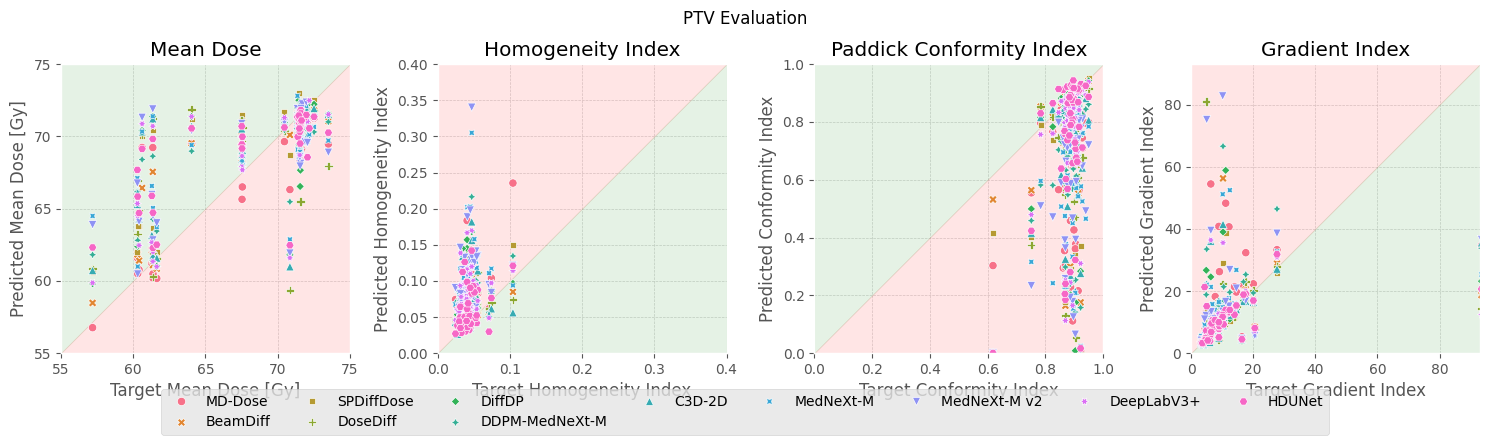

In [6]:
_ = pred_comparison.plot_ptv_evaluation()

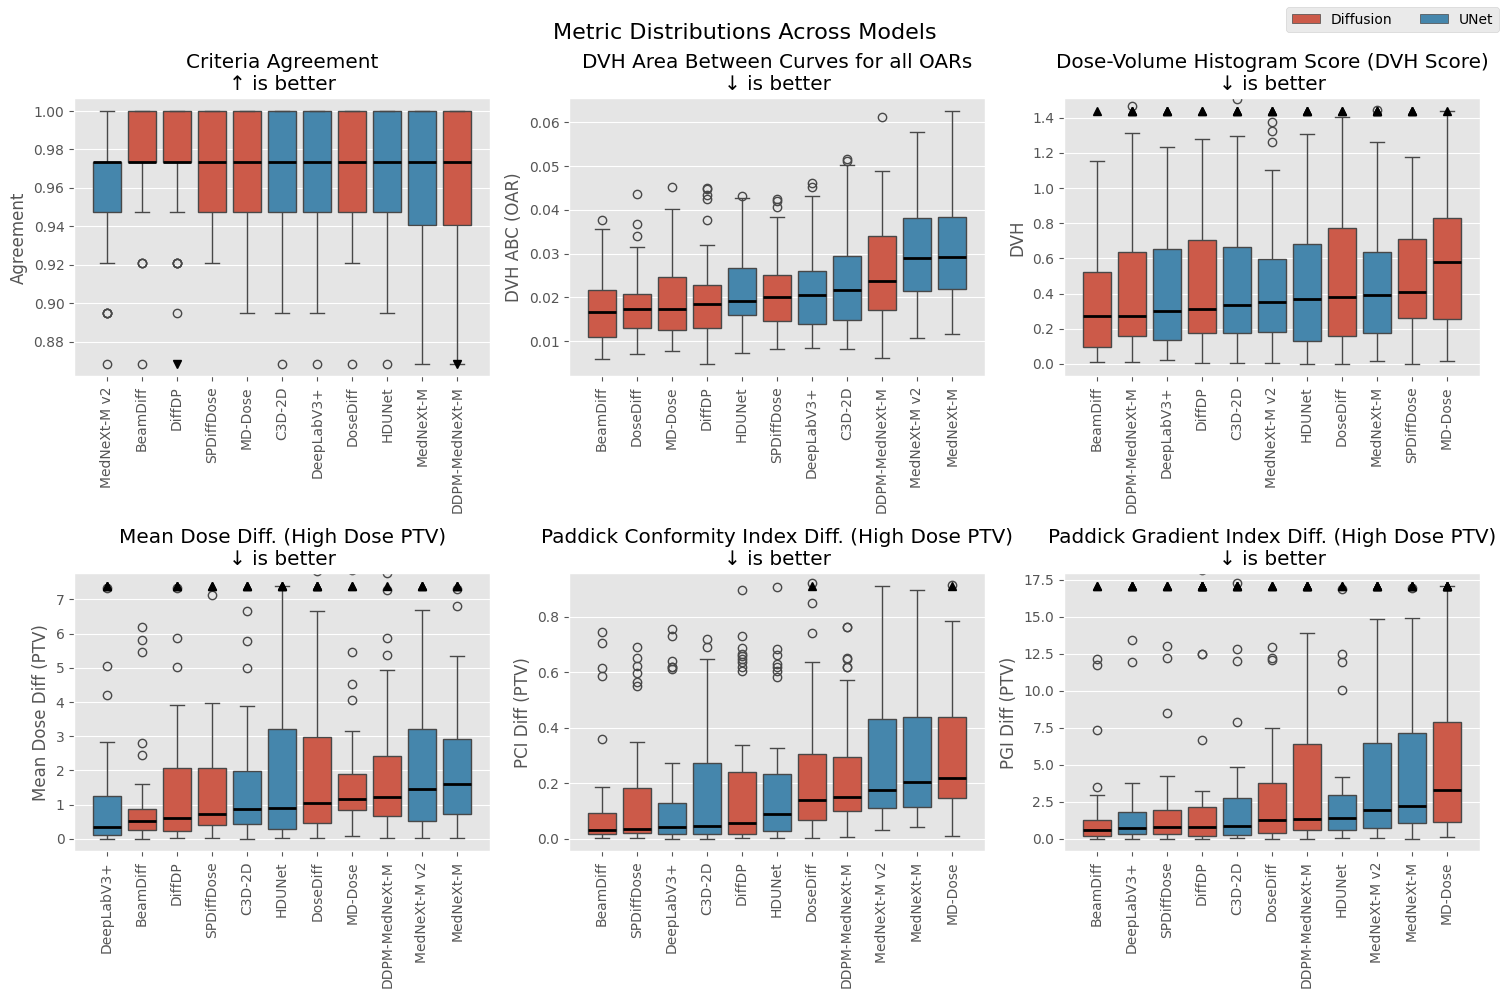

In [7]:
_ = pred_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=False)

Models were ranked per metric using a lexicographic ordering prioritizing median performance, followed by interquartile range and distributional spread as measures of robustness. Final model ranking was obtained by averaging ranks across metrics.

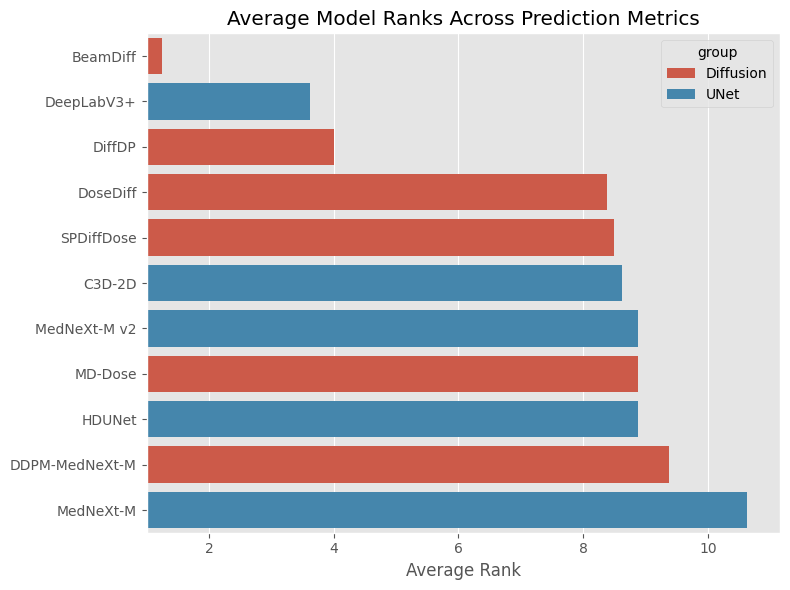

In [8]:
CORE_METRICS_PRED = [
  'vol_agreement/agreement_all',
  'vol_dvh_auc/OAR/diff',
  'vol_dvh',
  'vol_mean_dose/high/abs_diff',
]

ADDITIONAL_METRICS_PRED = [
  'vol_paddick_conformity_index/high/abs_diff',
  'vol_gradient_index/high/abs_diff'
]

mean_dose_diff = pd.concat([r.volume_metrics['vol_mean_dose/high/abs_diff'] for r in pred_comparison.results_list])
tau = mean_dose_diff.quantile(0.4)

median_dose_diffs = pd.Series([r.volume_metrics['vol_mean_dose/high/abs_diff'].median() for r in pred_comparison.results_list], index=pred_comparison.result_labels)

ranks = []
for metric in CORE_METRICS_PRED + ADDITIONAL_METRICS_PRED:
  scores = []
  iqr = []
  ranges = []
  for r in pred_comparison.results_list:
    scores.append(r.volume_metrics[metric].median())
    iqr.append(r.volume_metrics[metric].quantile(0.75) - r.volume_metrics[metric].quantile(0.25))
    ranges.append(r.volume_metrics[metric].max() - r.volume_metrics[metric].min())

  data = pd.DataFrame({
    'median': scores,
    'iqr': iqr,
    'range': ranges
  }, index=pred_comparison.result_labels).sort_values(['median', 'iqr', 'range'], ascending=[not is_higher_better(metric), True, True])
  data['rank'] = range(1, len(data) + 1)
  ranks.append(data['rank'])

ranks = pd.DataFrame(ranks, index=CORE_METRICS_PRED + ADDITIONAL_METRICS_PRED).T
ranks['core_rank'] = ranks[CORE_METRICS_PRED].mean(axis=1)
ranks['ptv_rank'] = ranks[ADDITIONAL_METRICS_PRED].mean(axis=1)
ranks['gate'] = median_dose_diffs
ranks['gate'] = [1 if diff <= tau else 0 for diff in ranks['gate']]
ranks['ptv_rank'] = ranks['gate'] * ranks['ptv_rank'] + (1 - ranks['gate']) * (len(ranks))

ranks['avg_rank'] = ranks[['core_rank', 'ptv_rank']].mean(axis=1)
ranks = ranks.sort_values('avg_rank')
ranks['group'] = pd.Series(pred_comparison.result_groups, index=pred_comparison.result_labels)
ranks = ranks.reset_index(names='model')

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(ranks, x='avg_rank', y='model', hue='group', ax=ax)
ax.set_xlabel('Average Rank')
ax.set_ylabel('')
ax.set_title('Average Model Ranks Across Prediction Metrics')
ax.set_xlim(1)
plt.tight_layout()

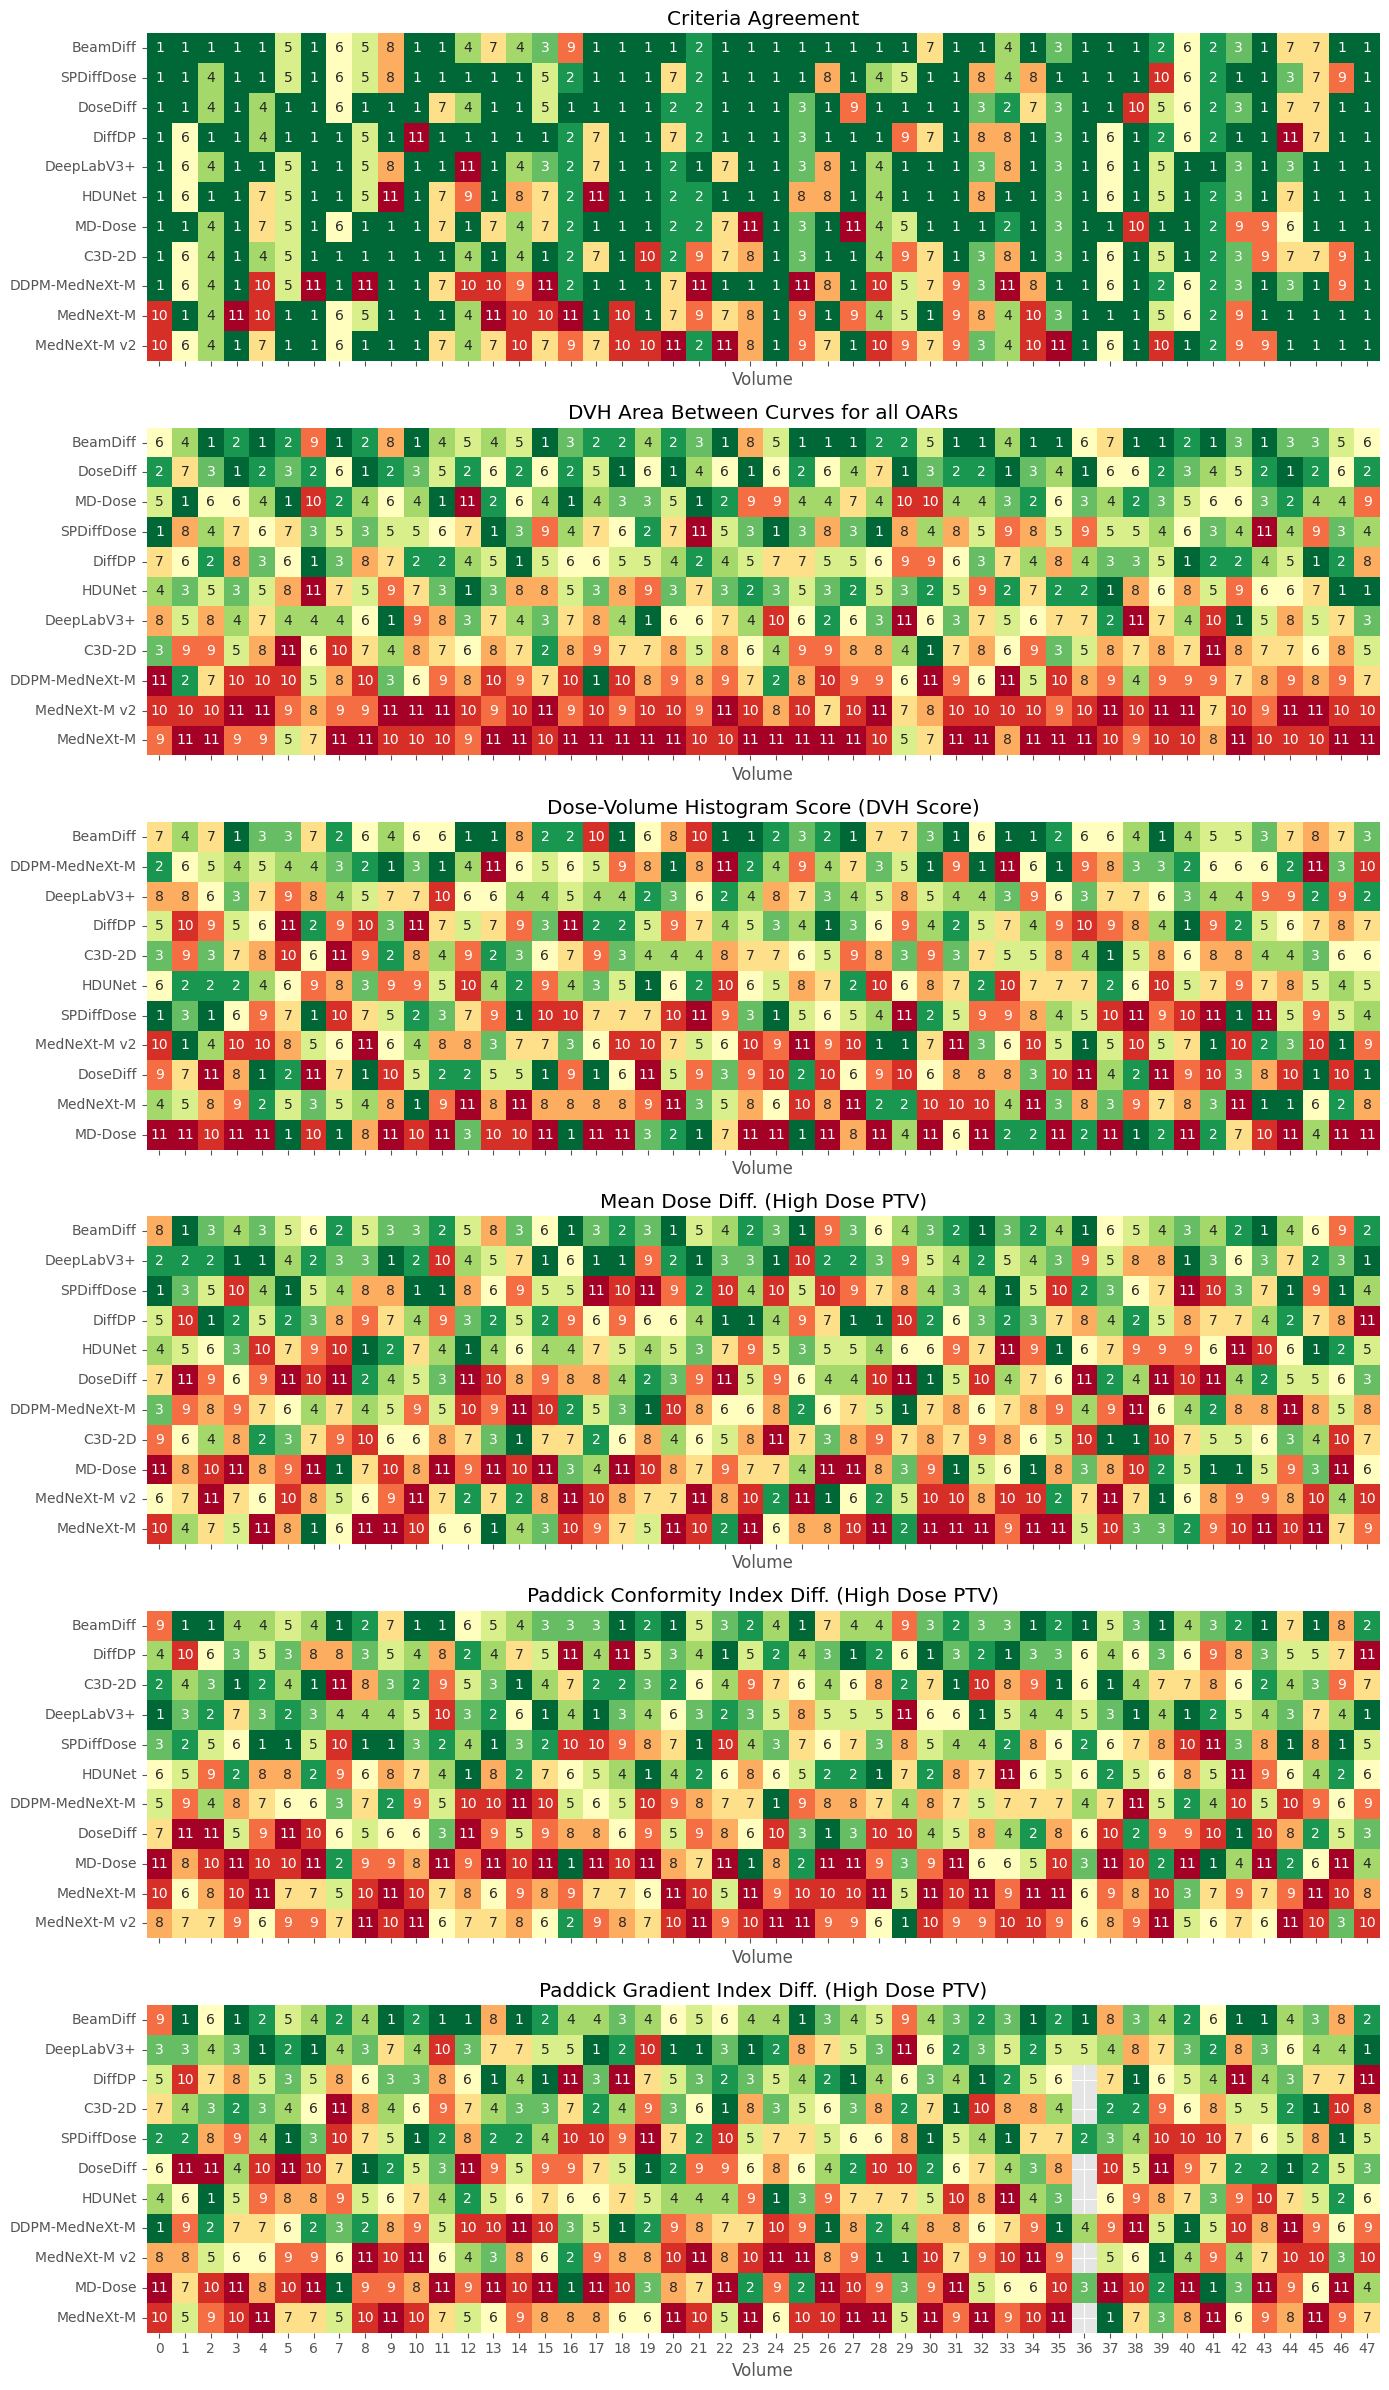

In [9]:
# Heatmaps: Model ranks per volume (sample) for each metric
def plot_rank_heatmaps(comparison, metrics, title_prefix=''):
    """
    Plot heatmaps showing model ranks per volume for each metric.

    Args:
        comparison: ModelComparison object
        metrics: List of metric names
    """
    n_metrics = len(metrics)
    fig, axes = plt.subplots(n_metrics, 1, figsize=(14, 4 * n_metrics), sharex=True)
    if n_metrics == 1:
        axes = [axes]

    # Get volume names from first result
    volumes = comparison.results_list[0].volume_metrics['file_name'].str.replace('.npz', '').tolist()

    for ax, metric in zip(axes, metrics):
        # Build matrix: rows=models, cols=volumes, values=metric value
        data = {}
        for result, label in zip(comparison.results_list, comparison.result_labels):
            row = {}
            for i, vol in enumerate(volumes):
                val = result.volume_metrics[metric].iloc[i]
                row[i] = val  # Use index instead of volume name
            data[label] = row

        df = pd.DataFrame(data).T  # models as rows, volumes as columns

        # Compute ranks per volume (column)
        higher_better = is_higher_better(metric)
        ranks_df = df.rank(ascending=not higher_better, method='min')

        # Sort rows by median rank
        row_order = ranks_df.median(axis=1).sort_values().index
        ranks_df = ranks_df.loc[row_order]

        # Plot heatmap (models on y-axis, volumes on x-axis)
        sns.heatmap(ranks_df, annot=True, fmt='.0f', cmap='RdYlGn_r',
                    vmin=1, vmax=len(comparison.result_labels),
                    cbar=False, ax=ax)
        ax.set_title(f'{title_prefix}{get_metric_label(metric)}')
        ax.set_xlabel('Volume')
        ax.set_ylabel('')

    plt.tight_layout()
    return fig

_ = plot_rank_heatmaps(pred_comparison, CORE_METRICS_PRED + ADDITIONAL_METRICS_PRED)


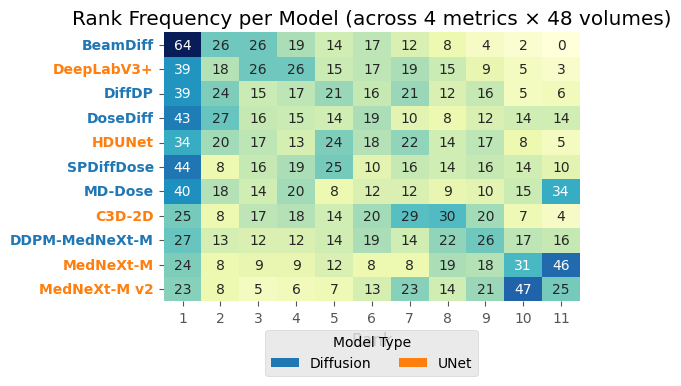

In [10]:
# Rank frequency heatmap: how often each model gets each rank
def plot_rank_frequency(comparison, metrics):
    """
    Plot heatmap showing how many times each model achieved each rank.
    Uses colored, bold labels to distinguish model groups (e.g., Diffusion vs UNet).

    Args:
        comparison: ModelComparison object
        metrics: List of metric names
    """
    n_models = len(comparison.result_labels)
    volumes = comparison.results_list[0].volume_metrics['file_name'].str.replace('.npz', '').tolist()

    # Collect all ranks for each model
    all_ranks = {label: [] for label in comparison.result_labels}

    for metric in metrics:
        # Build matrix: rows=models, cols=volumes
        data = {}
        for result, label in zip(comparison.results_list, comparison.result_labels):
            row = {}
            for i, vol in enumerate(volumes):
                val = result.volume_metrics[metric].iloc[i]
                row[i] = val
            data[label] = row

        df = pd.DataFrame(data).T

        # Compute ranks per volume
        higher_better = is_higher_better(metric)
        ranks_df = df.rank(ascending=not higher_better, method='min')

        # Collect ranks
        for label in comparison.result_labels:
            all_ranks[label].extend(ranks_df.loc[label].tolist())

    # Count frequency of each rank for each model
    rank_counts = {}
    for label in comparison.result_labels:
        counts = {}
        for r in range(1, n_models + 1):
            counts[r] = all_ranks[label].count(r)
        rank_counts[label] = counts

    count_df = pd.DataFrame(rank_counts).T

    # Sort by average rank (weighted by rank number)
    avg_rank = (count_df * count_df.columns).sum(axis=1) / count_df.sum(axis=1)
    count_df = count_df.loc[avg_rank.sort_values().index]

    # Create group mapping for sorted order
    label_to_group = dict(zip(comparison.result_labels, comparison.result_groups))
    sorted_groups = [label_to_group[label] for label in count_df.index]

    # Define group colors
    unique_groups = list(dict.fromkeys(comparison.result_groups))  # Preserve order
    group_colors = {'Diffusion': '#1f77b4', 'UNet': '#ff7f0e'}  # Blue for Diffusion, Orange for UNet
    # Fallback for other group names
    default_colors = plt.cm.tab10.colors
    for i, g in enumerate(unique_groups):
        if g not in group_colors:
            group_colors[g] = default_colors[i % len(default_colors)]

    # Plot
    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(count_df, annot=True, fmt='d', cmap='YlGnBu',
                cbar=False, ax=ax)
    ax.set_xlabel('Rank')
    ax.set_ylabel('')
    ax.set_title(f'Rank Frequency per Model (across {len(metrics)} metrics × {len(volumes)} volumes)')

    # Color and bold the y-axis labels based on group
    if comparison.has_groups:
        for tick_label, group in zip(ax.get_yticklabels(), sorted_groups):
            color = group_colors.get(group, 'black')
            tick_label.set_color(color)
            tick_label.set_fontweight('bold')

        # Add legend at the bottom
        from matplotlib.patches import Patch
        legend_handles = [Patch(facecolor=group_colors[g], label=g) for g in unique_groups]
        ax.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, -0.08),
                  ncol=len(unique_groups), title='Model Type')

    plt.tight_layout()
    return fig

_ = plot_rank_frequency(pred_comparison, CORE_METRICS_PRED)

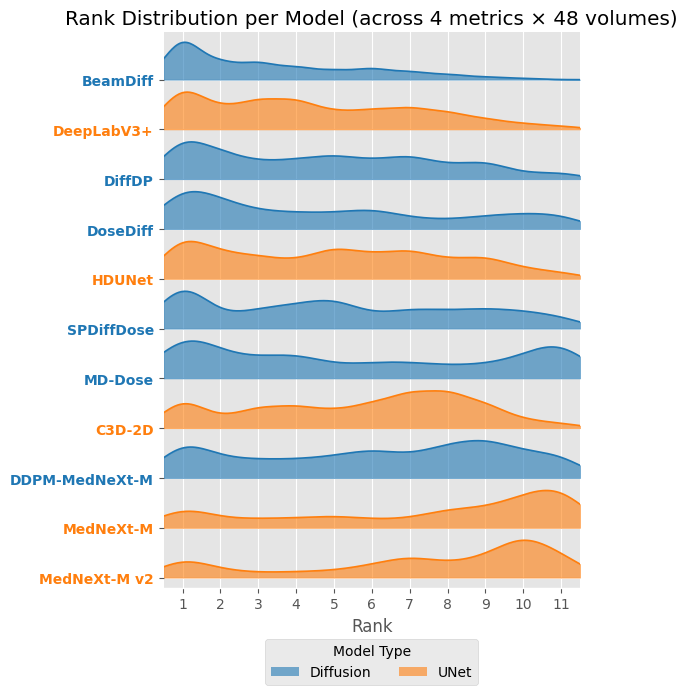

In [11]:
import numpy as np
from scipy.stats import gaussian_kde
from matplotlib.patches import Patch

def plot_rank_frequency_ridgeline(comparison, metrics):
    """
    Ridgeline chart showing the distribution of ranks for each model.
    Models are sorted by average rank (best at bottom).
    """
    n_models = len(comparison.result_labels)
    volumes = comparison.results_list[0].volume_metrics['file_name'].str.replace('.npz', '').tolist()

    # Collect all ranks for each model (same logic as plot_rank_frequency)
    all_ranks = {label: [] for label in comparison.result_labels}

    for metric in metrics:
        data = {}
        for result, label in zip(comparison.results_list, comparison.result_labels):
            row = {}
            for i, vol in enumerate(volumes):
                val = result.volume_metrics[metric].iloc[i]
                row[i] = val
            data[label] = row

        df = pd.DataFrame(data).T
        higher_better = is_higher_better(metric)
        ranks_df = df.rank(ascending=not higher_better, method='min')

        for label in comparison.result_labels:
            all_ranks[label].extend(ranks_df.loc[label].tolist())

    # Sort models by average rank (reversed so best is at bottom)
    avg_ranks = {label: np.mean(ranks) for label, ranks in all_ranks.items()}
    sorted_labels = sorted(avg_ranks, key=avg_ranks.get, reverse=True)

    # Group colors
    label_to_group = dict(zip(comparison.result_labels, comparison.result_groups))
    unique_groups = list(dict.fromkeys(comparison.result_groups))
    group_colors = {'Diffusion': '#1f77b4', 'UNet': '#ff7f0e'}
    default_colors = plt.cm.tab10.colors
    for i, g in enumerate(unique_groups):
        if g not in group_colors:
            group_colors[g] = default_colors[i % len(default_colors)]

    # Create figure
    fig, ax = plt.subplots(figsize=(6, n_models * 0.55 + 1))

    scale = 0.75  # Max height of each ridge
    x = np.linspace(0.5, n_models + 0.5, 300)

    for i, label in enumerate(sorted_labels):
        ranks = np.array(all_ranks[label])
        group = label_to_group[label]
        color = group_colors.get(group, 'black')

        # KDE with bandwidth tuned for discrete ranks
        kde = gaussian_kde(ranks, bw_method=0.2)
        density = kde(x)
        density = density / density.max() * scale

        baseline = i
        ax.fill_between(x, baseline, baseline + density, alpha=0.6, color=color, zorder=n_models - i)
        ax.plot(x, baseline + density, color=color, linewidth=1.2, zorder=n_models - i)

    # Y-axis: model labels
    ax.set_yticks(range(len(sorted_labels)))
    ax.set_yticklabels(sorted_labels)

    # Color y-tick labels by group
    if comparison.has_groups:
        for tick_label, model_label in zip(ax.get_yticklabels(), sorted_labels):
            group = label_to_group[model_label]
            color = group_colors.get(group, 'black')
            tick_label.set_color(color)
            tick_label.set_fontweight('bold')

    ax.set_xlim(0.5, n_models + 0.5)
    ax.set_ylim(-0.2, len(sorted_labels) - 1 + scale + 0.2)
    ax.set_xticks(range(1, n_models + 1))
    ax.set_xlabel('Rank')
    ax.set_title(f'Rank Distribution per Model (across {len(metrics)} metrics × {len(volumes)} volumes)')

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)

    # Legend
    if comparison.has_groups:
        legend_handles = [Patch(facecolor=group_colors[g], alpha=0.6, label=g) for g in unique_groups]
        ax.legend(handles=legend_handles, loc='upper center', bbox_to_anchor=(0.5, -0.08),
                  ncol=len(unique_groups), title='Model Type')

    plt.tight_layout()
    return fig

_ = plot_rank_frequency_ridgeline(pred_comparison, CORE_METRICS_PRED)

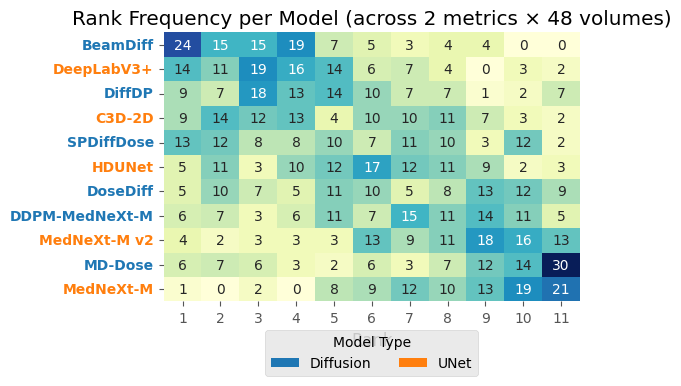

In [12]:
_ = plot_rank_frequency(pred_comparison, ADDITIONAL_METRICS_PRED)

/var/folders/zl/w6zt87md14j4524by47x78j00000gq/T/ipykernel_95388/4118823315.py:60: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  base_cmap = plt.cm.get_cmap('tab10', len(comparison.result_labels))


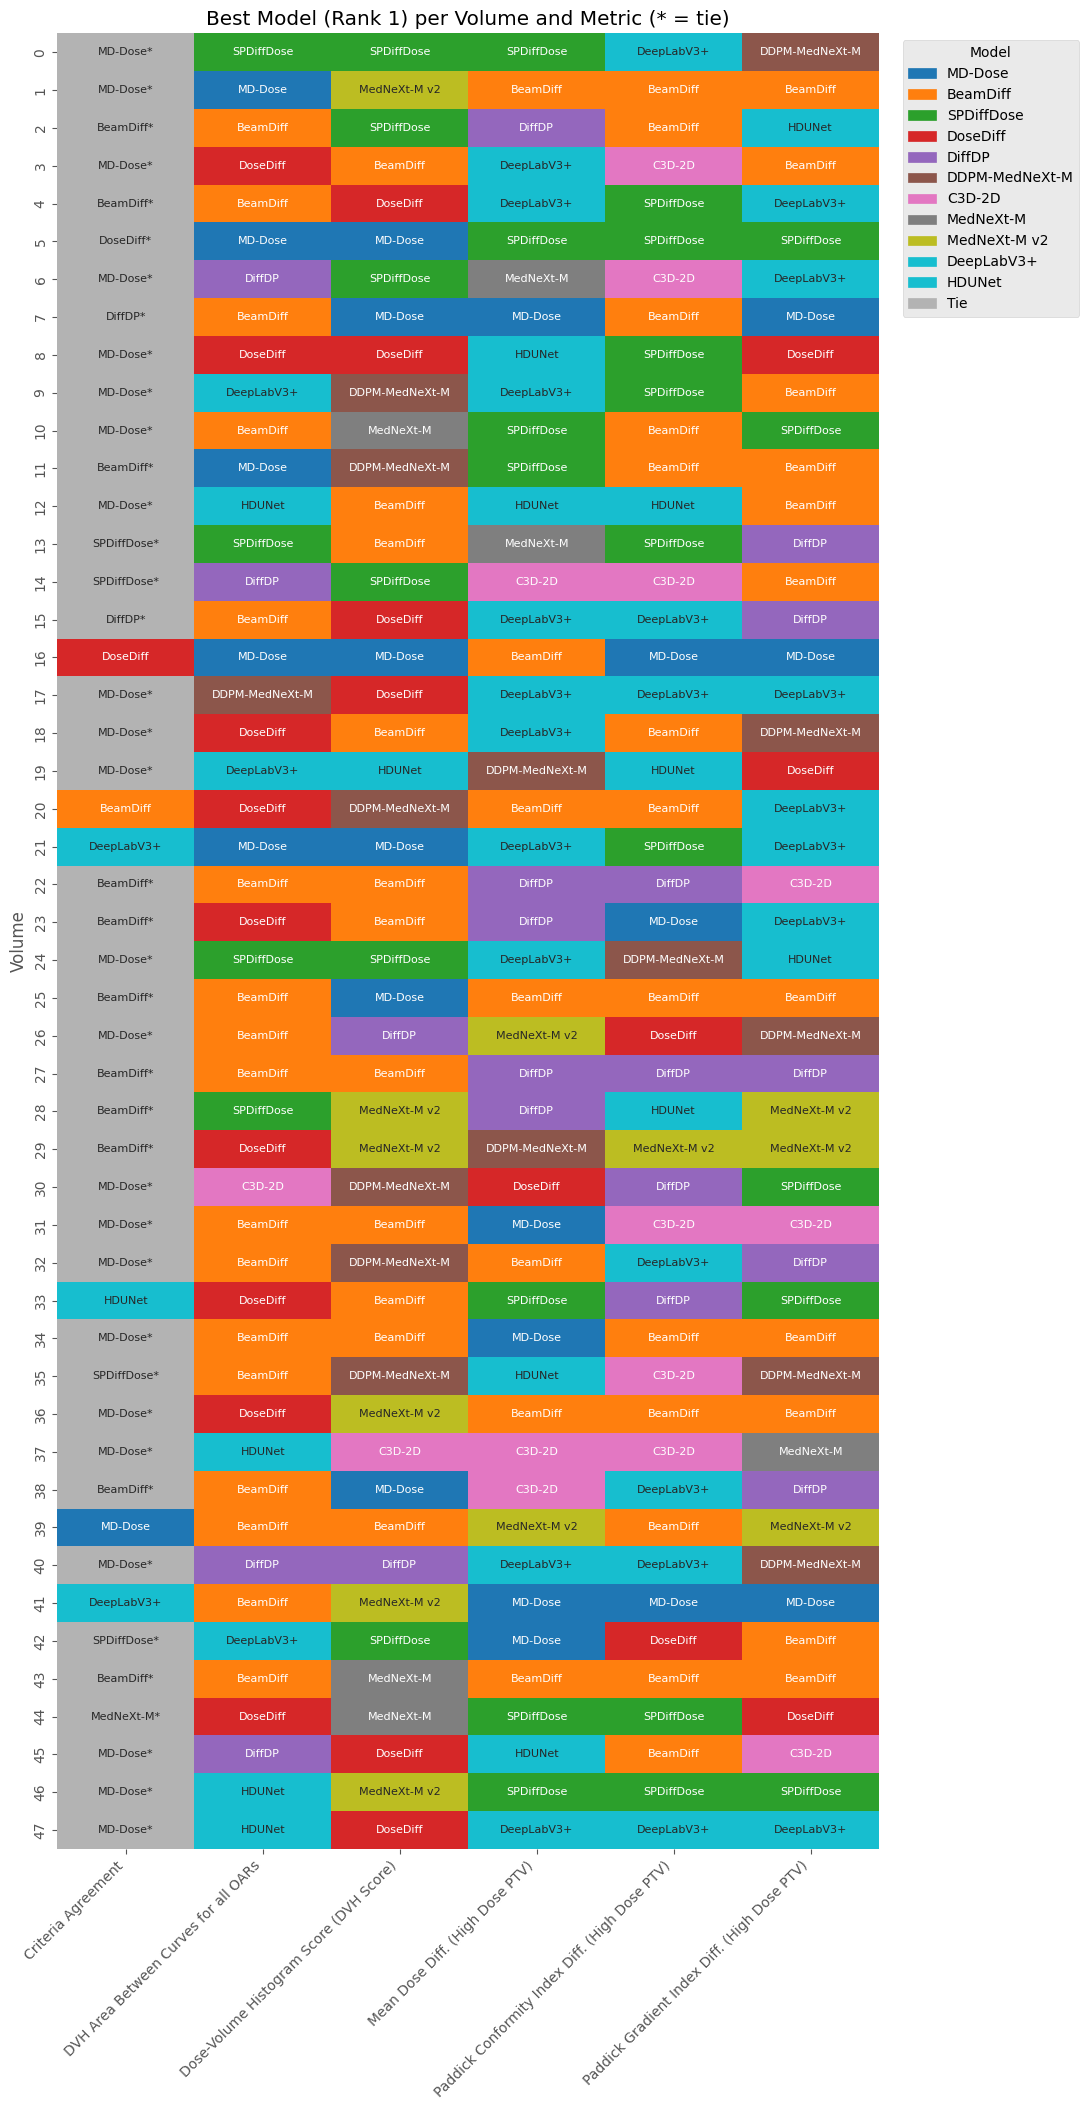

In [13]:
# Best model per volume and metric
def plot_best_models(comparison, metrics):
    """
    Plot a table showing the best model (rank 1) for each volume and metric.
    Marks cells with '*' if multiple models share rank 1.
    """
    # Get volume names from first result
    volumes = comparison.results_list[0].volume_metrics['file_name'].str.replace('.npz', '').tolist()
    n_volumes = len(volumes)

    # Build result matrix: rows=metrics, cols=volumes
    best_models = []

    for metric in metrics:
        # Build matrix: rows=models, cols=volumes
        data = {}
        for result, label in zip(comparison.results_list, comparison.result_labels):
            row = {}
            for i, vol in enumerate(volumes):
                val = result.volume_metrics[metric].iloc[i]
                row[i] = val
            data[label] = row

        df = pd.DataFrame(data).T  # models as rows, volumes as columns

        # Compute ranks per volume (column)
        higher_better = is_higher_better(metric)
        ranks_df = df.rank(ascending=not higher_better, method='min')

        # Find best model(s) for each volume
        row_data = {}
        for vol_idx in range(n_volumes):
            rank_1_models = ranks_df.index[ranks_df[vol_idx] == 1].tolist()
            if len(rank_1_models) > 1:
                row_data[vol_idx] = rank_1_models[0] + '*'  # Mark tie with *
            else:
                row_data[vol_idx] = rank_1_models[0]
        best_models.append(row_data)

    result_df = pd.DataFrame(best_models, index=[get_metric_label(m) for m in metrics])

    # Transpose: volumes as rows, metrics as columns
    result_df = result_df.T

    # Plot as heatmap with text annotations
    fig, ax = plt.subplots(figsize=(len(metrics) * 1.5 + 2, n_volumes * 0.4 + 2))

    # Create numeric mapping for coloring (ties get a special index)
    model_to_num = {label: i for i, label in enumerate(comparison.result_labels)}
    tie_idx = len(comparison.result_labels)  # Special index for ties

    def map_to_num(val):
        if val.endswith('*'):
            return tie_idx
        return model_to_num[val]

    numeric_df = result_df.apply(lambda col: col.map(map_to_num))

    # Use a colormap with enough distinct colors + gray for ties
    base_cmap = plt.cm.get_cmap('tab10', len(comparison.result_labels))
    colors = [base_cmap(i) for i in range(len(comparison.result_labels))]
    colors.append((0.7, 0.7, 0.7, 1.0))  # Gray for ties
    from matplotlib.colors import ListedColormap
    cmap = ListedColormap(colors)

    sns.heatmap(numeric_df, annot=result_df.values, fmt='', cmap=cmap,
                vmin=0, vmax=len(comparison.result_labels),
                cbar=False, ax=ax, annot_kws={'fontsize': 8})
    ax.set_xlabel('')
    ax.set_ylabel('Volume')
    ax.set_title('Best Model (Rank 1) per Volume and Metric (* = tie)')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')

    # Add legend
    handles = [plt.Rectangle((0, 0), 1, 1, color=colors[i]) for i in range(len(comparison.result_labels))]
    handles.append(plt.Rectangle((0, 0), 1, 1, color=colors[-1]))
    labels = list(comparison.result_labels) + ['Tie']
    ax.legend(handles, labels, loc='upper left', bbox_to_anchor=(1.02, 1), title='Model')

    plt.tight_layout()
    return fig

_ = plot_best_models(pred_comparison, CORE_METRICS_PRED + ADDITIONAL_METRICS_PRED)

In [14]:
ranks

,model,vol_agreement/agreement_all,vol_dvh_auc/OAR/diff,vol_dvh,vol_mean_dose/high/abs_diff,vol_paddick_conformity_index/high/abs_diff,vol_gradient_index/high/abs_diff,core_rank,ptv_rank,gate,avg_rank,group
0,BeamDiff,2,1,1,2,1,1,1.50,1.0,1,1.250,Diffusion
1,DeepLabV3+,8,7,3,1,3,2,4.75,2.5,1,3.625,UNet
2,DiffDP,3,4,4,3,5,4,3.50,4.5,1,4.000,Diffusion
3,DoseDiff,6,2,8,7,7,6,5.75,11.0,0,8.375,Diffusion
4,SPDiffDose,4,6,10,4,2,3,6.00,11.0,0,8.500,Diffusion
5,C3D-2D,7,8,5,5,4,5,6.25,11.0,0,8.625,UNet
6,MedNeXt-M v2,1,10,6,10,9,9,6.75,11.0,0,8.875,UNet
7,MD-Dose,5,3,11,8,11,11,6.75,11.0,0,8.875,Diffusion
8,HDUNet,9,5,7,6,6,8,6.75,11.0,0,8.875,UNet
9,DDPM-MedNeXt-M,11,9,2,9,8,7,7.75,11.0,0,9.375,Diffusion


In [15]:
filtered_pred_comparison = ModelComparison([
    beamdiff_199_pred,
    diffdp_199_pred,
    deeplabv3plus_199_pred
  ], [
    'BeamDiff',
    'DiffDP',
    'DeepLabV3+'
  ], [
    'Diffusion',
    'Diffusion',
    'UNet'
  ]
)

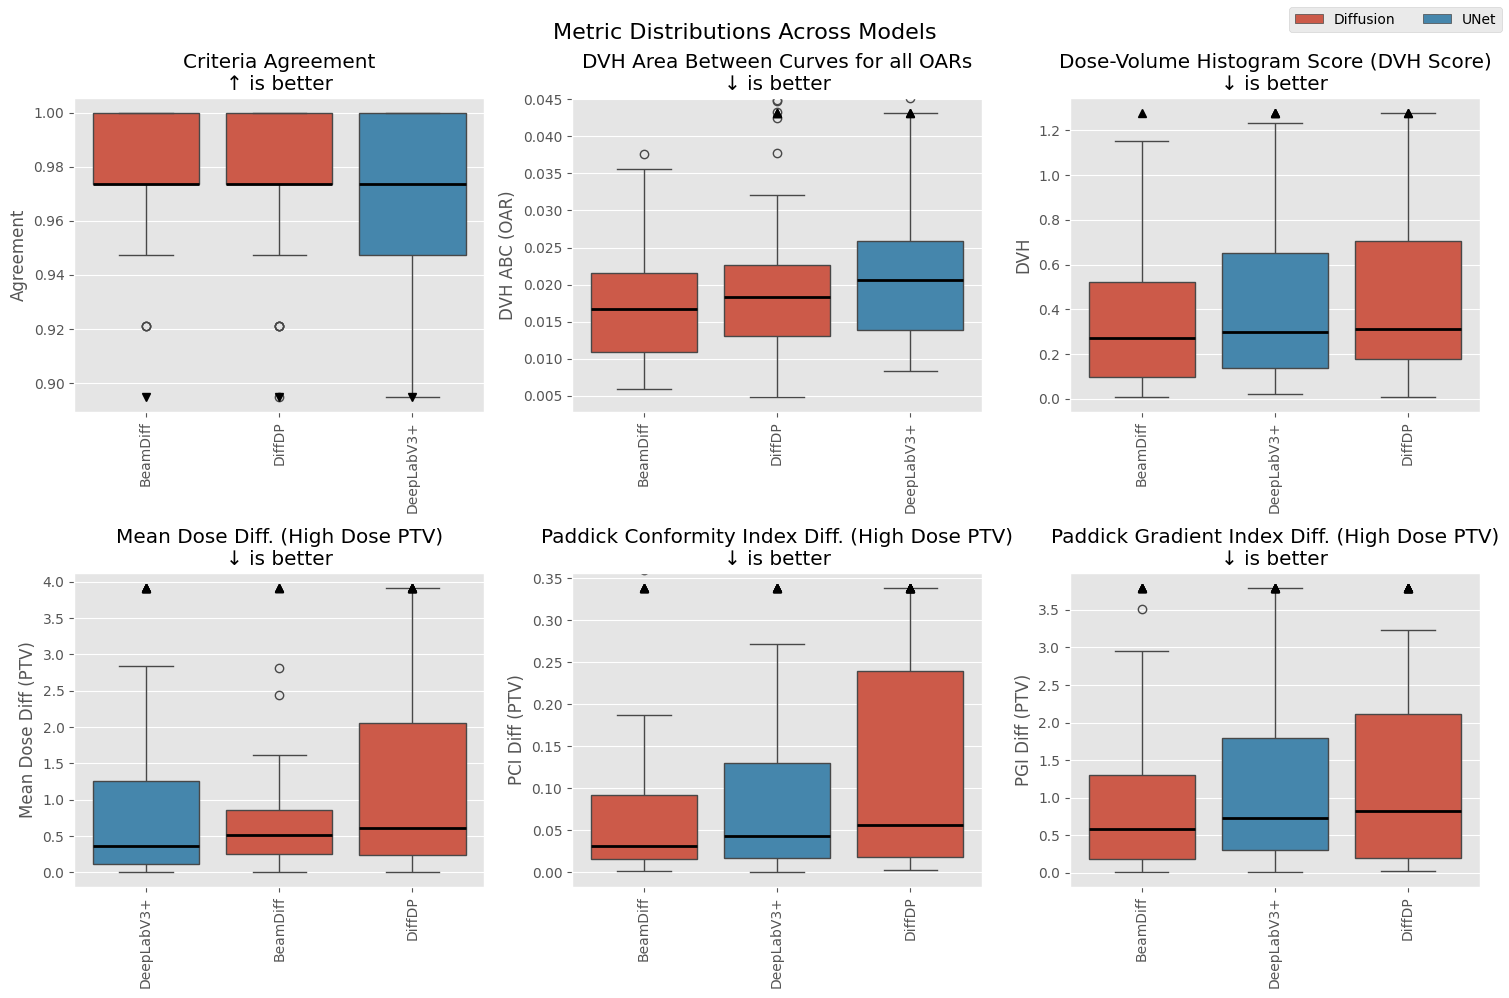

In [16]:
_ = filtered_pred_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=False)

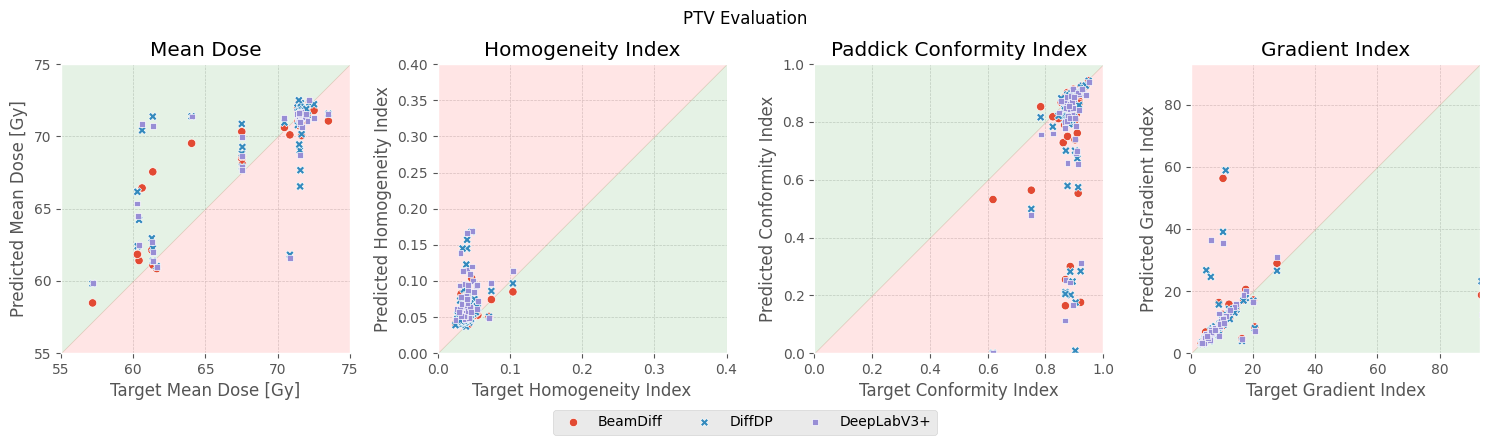

In [17]:
_ = filtered_pred_comparison.plot_ptv_evaluation()

### High Gradient Index

This is due to wrong dose levels in PTV (see mean_dose, eg. 73 vs. 68 Gy) making the gradient index calculation meaningless.

In [18]:
df = dosediff_199_pred.volume_metrics
df = df[df['vol_gradient_index/high/abs_diff'] > 5000]
df[['vol_mean_dose/high/target', 'vol_mean_dose/high/pred', 'vol_gradient_index/high/abs_diff', 'vol_gradient_index/high/target', 'vol_gradient_index/high/pred']]

,vol_mean_dose/high/target,vol_mean_dose/high/pred,vol_gradient_index/high/abs_diff,vol_gradient_index/high/target,vol_gradient_index/high/pred
5,73.514397,67.954445,34834.210938,10.288342,34844.5


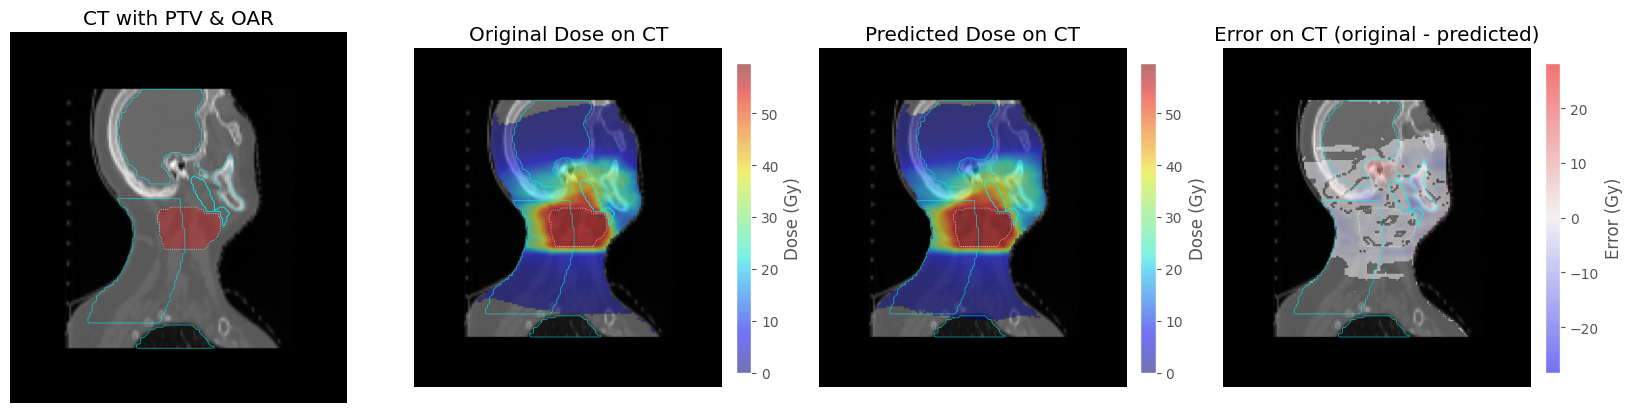

In [19]:
_ = dosediff_199_pred.for_sample('HNSCC-01-0078+A4Ac+MOS_12319').visualise_slice_with_ct(80)

### Constraints

<Axes: >

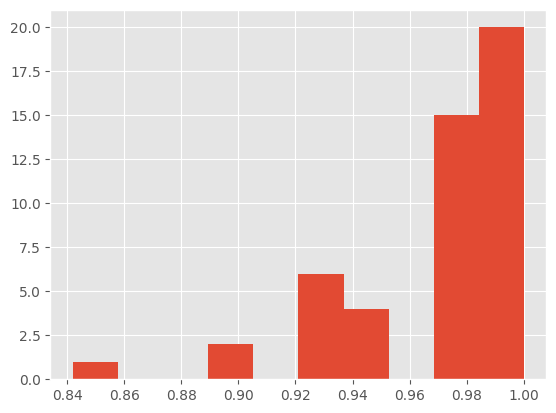

In [20]:
deeplabv3plus_l2_199_pred.volume_metrics['vol_agreement/agreement_all'].hist()

In [21]:
deeplabv3plus_l2_199_pred.volume_metrics['vol_agreement/agreement_all'].unique() * 38

array([38.        , 36.99999928, 35.00000012, 36.00000083, 32.00000024,
       33.9999994 ])

In [22]:
from constraints import ConstraintLibrary, FractionationType, GDPHMM_TO_CONSTRAINT_ORGAN
from data import GDPHMM_OAR_V3
from evaluator import GDPHMM_UNIQUE_OAR

library = ConstraintLibrary()

mapped_organs = {}
unmapped = []
for organ in GDPHMM_UNIQUE_OAR:
    constraint_organ = GDPHMM_TO_CONSTRAINT_ORGAN.get(organ)
    if constraint_organ:
        if constraint_organ not in mapped_organs:
            mapped_organs[constraint_organ] = []
        mapped_organs[constraint_organ].append(organ)
    else:
        unmapped.append(organ)

print(f'Total GDPHMM_UNIQUE_OAR organs: {len(GDPHMM_UNIQUE_OAR)}')
print(f'Mapped to constraint organs: {len(GDPHMM_UNIQUE_OAR) - len(unmapped)}')
print(f'Unmapped (skipped): {len(unmapped)} -> {unmapped}')
print(f'Unique constraint organs: {len(mapped_organs)}')

print()
total_constraints = 0
for constraint_organ, gdphmm_organs in sorted(mapped_organs.items()):
    constraints = library.get_constraints(organ=constraint_organ, fractionation=FractionationType.CONVENTIONAL)
    n = len(constraints)
    total_constraints += n
    grades = {}
    for c in constraints:
        g = c.grade.value if c.grade else 'ungraded'
        grades[g] = grades.get(g, 0) + 1
    grade_str = ', '.join(f'{k}: {v}' for k, v in sorted(grades.items()))
    src = ' / '.join(gdphmm_organs)
    print(f'  {constraint_organ:35s} <- {src:30s}: {n:2d} constraints  [{grade_str}]')

print(f'\nTotal unique constraint organs: {len(mapped_organs)}')
print(f'Total constraints evaluated: {total_constraints}')


Total GDPHMM_UNIQUE_OAR organs: 26
Mapped to constraint organs: 23
Unmapped (skipped): 3 -> ['Shoulders', 'Posterior_Neck', 'OCavity-PTV']
Unique constraint organs: 18

  BoneMandible                        <- Mandible-PTV                  :  3 constraints  [mandatory: 1, optimal: 1, ungraded: 1]
  Brain                               <- Brain                         :  2 constraints  [ungraded: 2]
  Brainstem                           <- BrainStem_03                  :  2 constraints  [ungraded: 2]
  Cochlea                             <- Cochlea_R / Cochlea_L         :  1 constraints  [ungraded: 1]
  Esophagus                           <- Esophagus                     :  4 constraints  [ungraded: 4]
  Eye                                 <- Eyes                          :  1 constraints  [ungraded: 1]
  Larynx                              <- Larynx-PTV                    :  4 constraints  [ungraded: 4]
  Lens                                <- Lens_L / Lens_R               :  1 constrai

### Continued Training

In [23]:
beamdiff_pred_comparison = ModelComparison([
	beamdiff_099_pred,
  beamdiff_199_pred,
], [
  '99 epochs',
  '199 epochs',
])

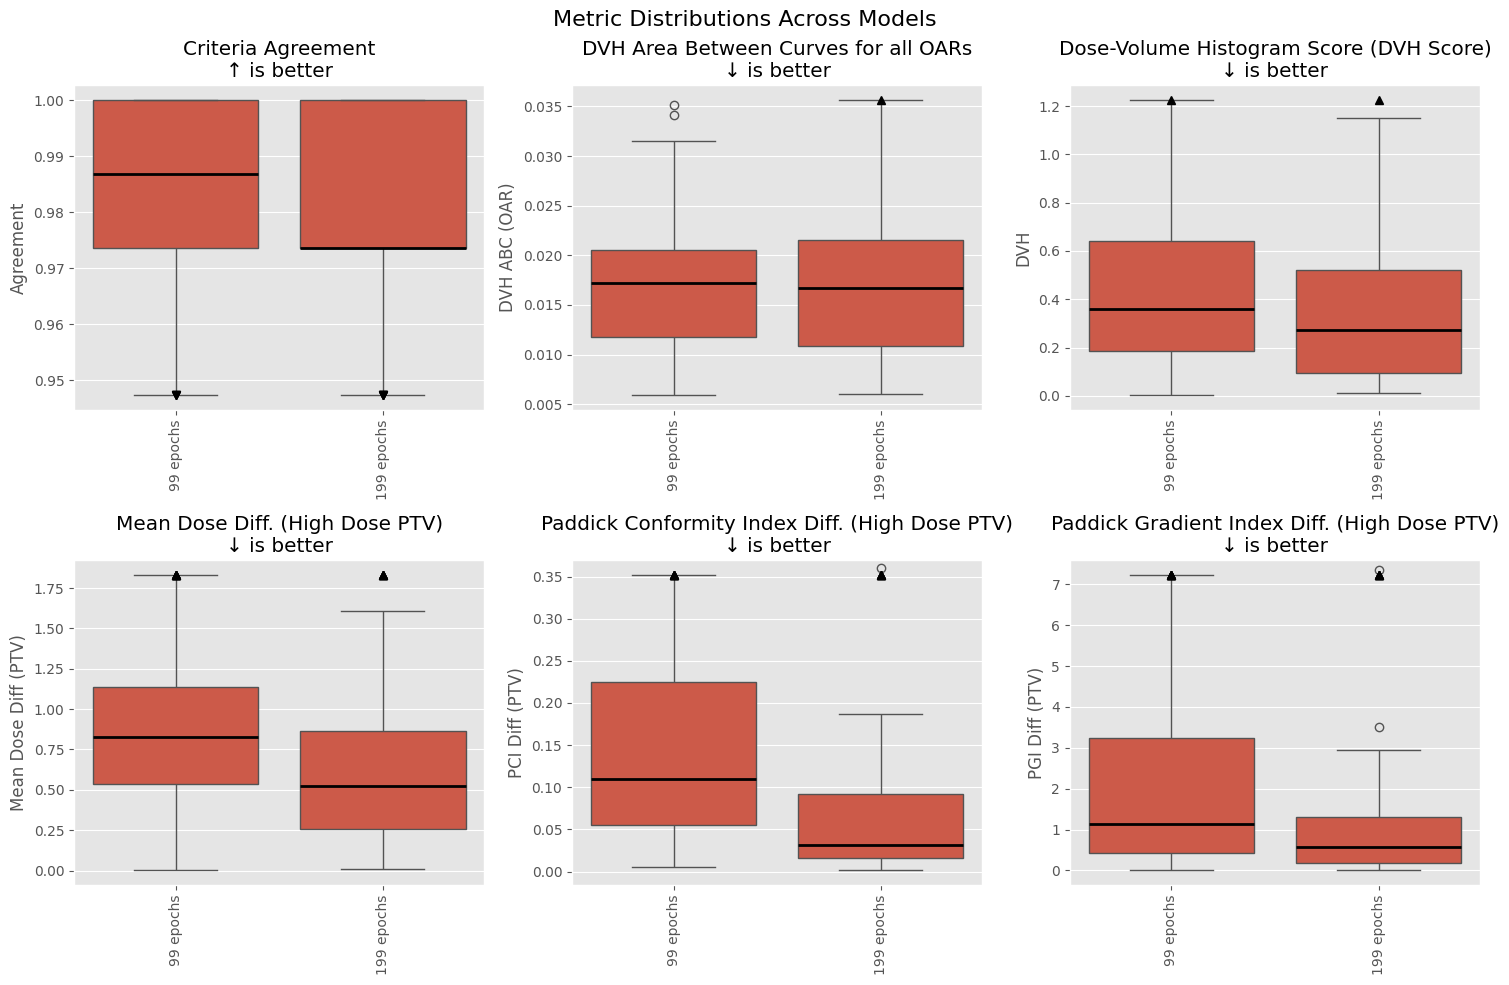

In [24]:
_ = beamdiff_pred_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

In [25]:
pred_099_comparison = ModelComparison([
  mamba_099_pred,
  beamdiff_099_pred,
  spdiffdose_099_pred,
  dosediff_099_pred,
  diffdp_099_pred,
  ddpm_mednext_m_099_pred,
  c3d_2d_099_pred,
  mednext_m_099_pred,
  mednext_v2_m_099_pred,
  deeplabv3plus_099_pred,
  hdunet_099_pred,
], [
  'MD-Dose',
  'BeamDiff',
  'SPDiffDose',
  'DoseDiff',
  'DiffDP',
  'DDPM-MedNeXt-M',
  'C3D-2D',
  'MedNeXt-M',
  'MedNeXt-M v2',
  'DeepLabV3+',
  'HDUNet',
], [
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'UNet',
  'UNet',
  'UNet',
  'UNet',
  'UNet',
])

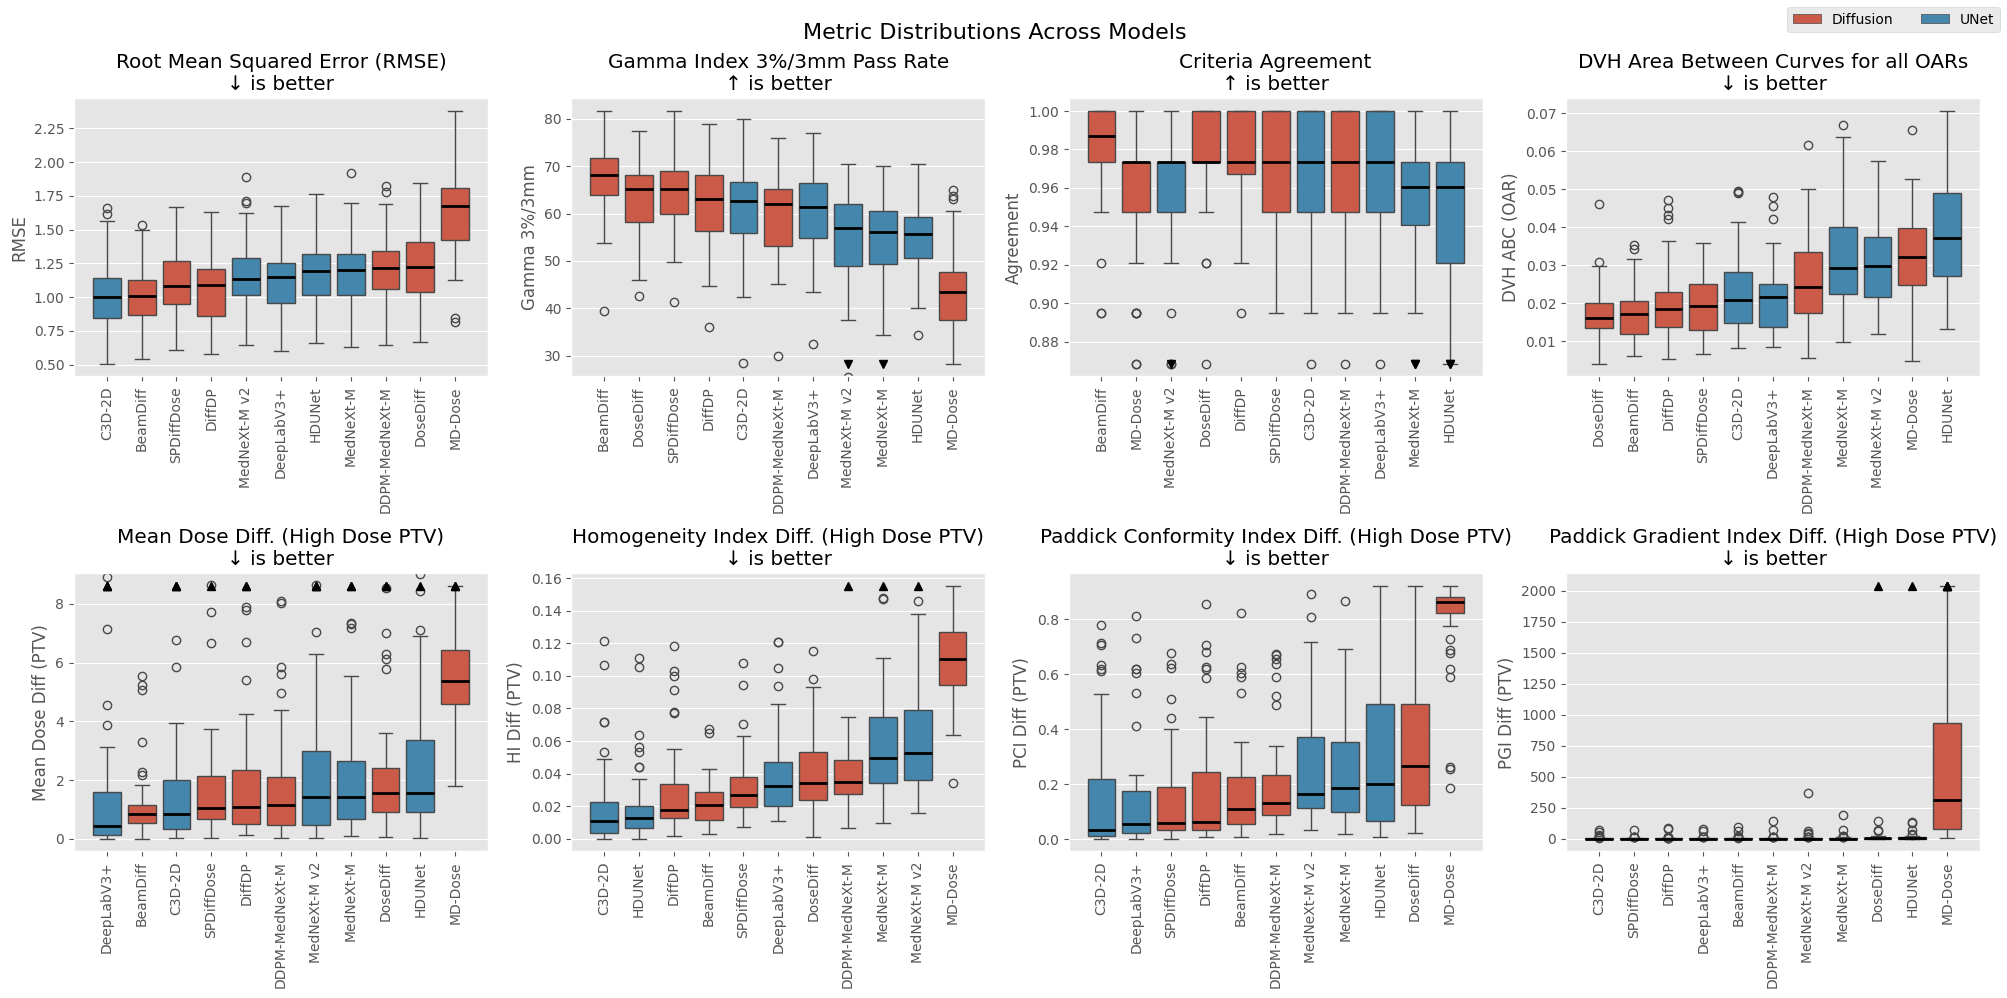

In [26]:
_ = pred_099_comparison.plot_metric_distributions(METRICS_PLAN_EXTENDED, sort=True, outliers=False)

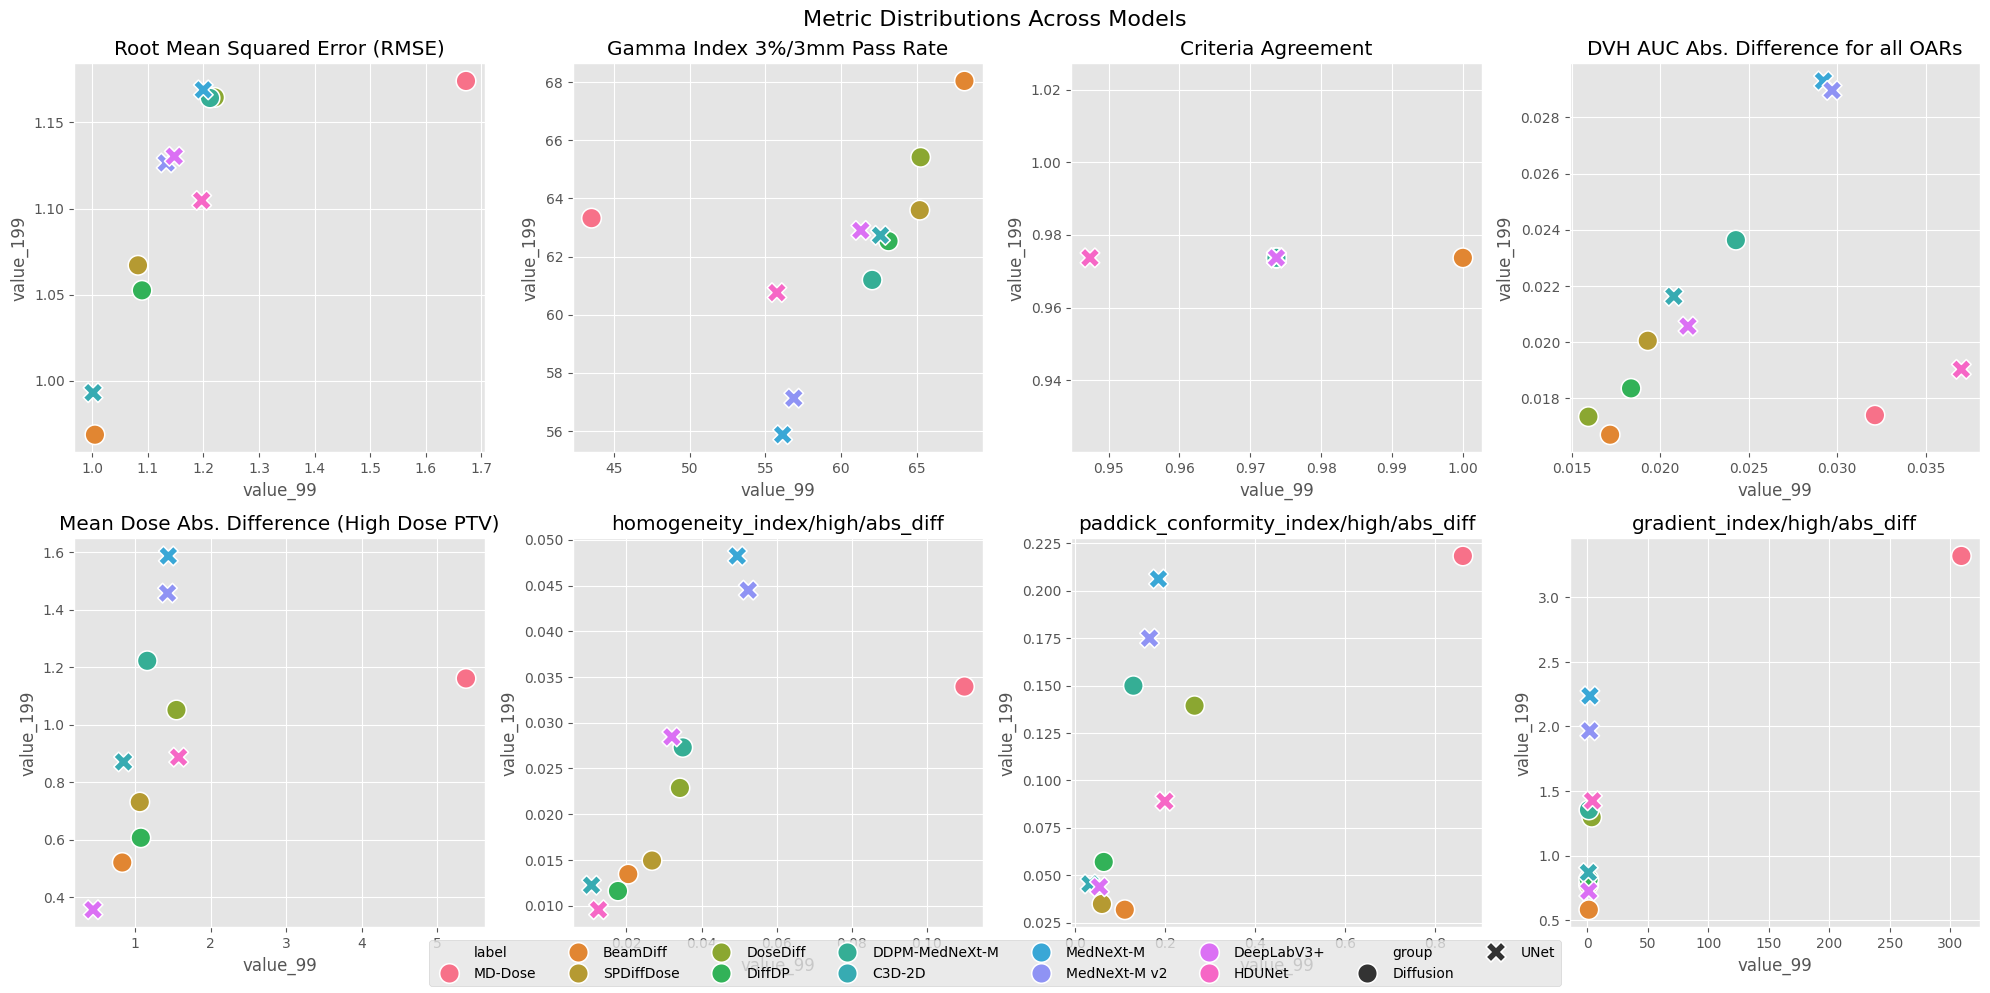

In [82]:
n_rows = 2
n_cols = 4

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), squeeze=False)
axes = axes.flatten()


for i, metric in enumerate(METRICS_RELEVANT_EXTENDED):
  values_99 = []
  values_199 = []
  for result_99, result_199 in zip(pred_099_comparison.results_list, pred_comparison.results_list):
    values_99.append(result_99.volume_metrics[metric].median())
    values_199.append(result_199.volume_metrics[metric].median())

  df = pd.DataFrame({'label': pred_099_comparison.result_labels, 'value_99': values_99, 'value_199': values_199, 'group': pred_099_comparison.result_groups})

  sns.scatterplot(df, x='value_99', y='value_199', hue='label', style='group', s=200, ax=axes[i])
  axes[i].set_title(f'{get_metric_label(metric)}')

fig.suptitle('Metric Distributions Across Models', fontsize=16)
fig.tight_layout()

if pred_099_comparison.has_groups:
  handles, labels = axes[0].get_legend_handles_labels()
  fig.legend(handles, labels, loc='lower center', title='', ncol=8)

  for ax in axes:
    ax.get_legend().remove()

In [27]:
deeplabv3plus_pred_comparison = ModelComparison([
  deeplabv3plus_199_pred, deeplabv3plus_l2_199_pred
], [
  'DeepLabV3+',
  'DeepLabV3+ L2 Loss'
])

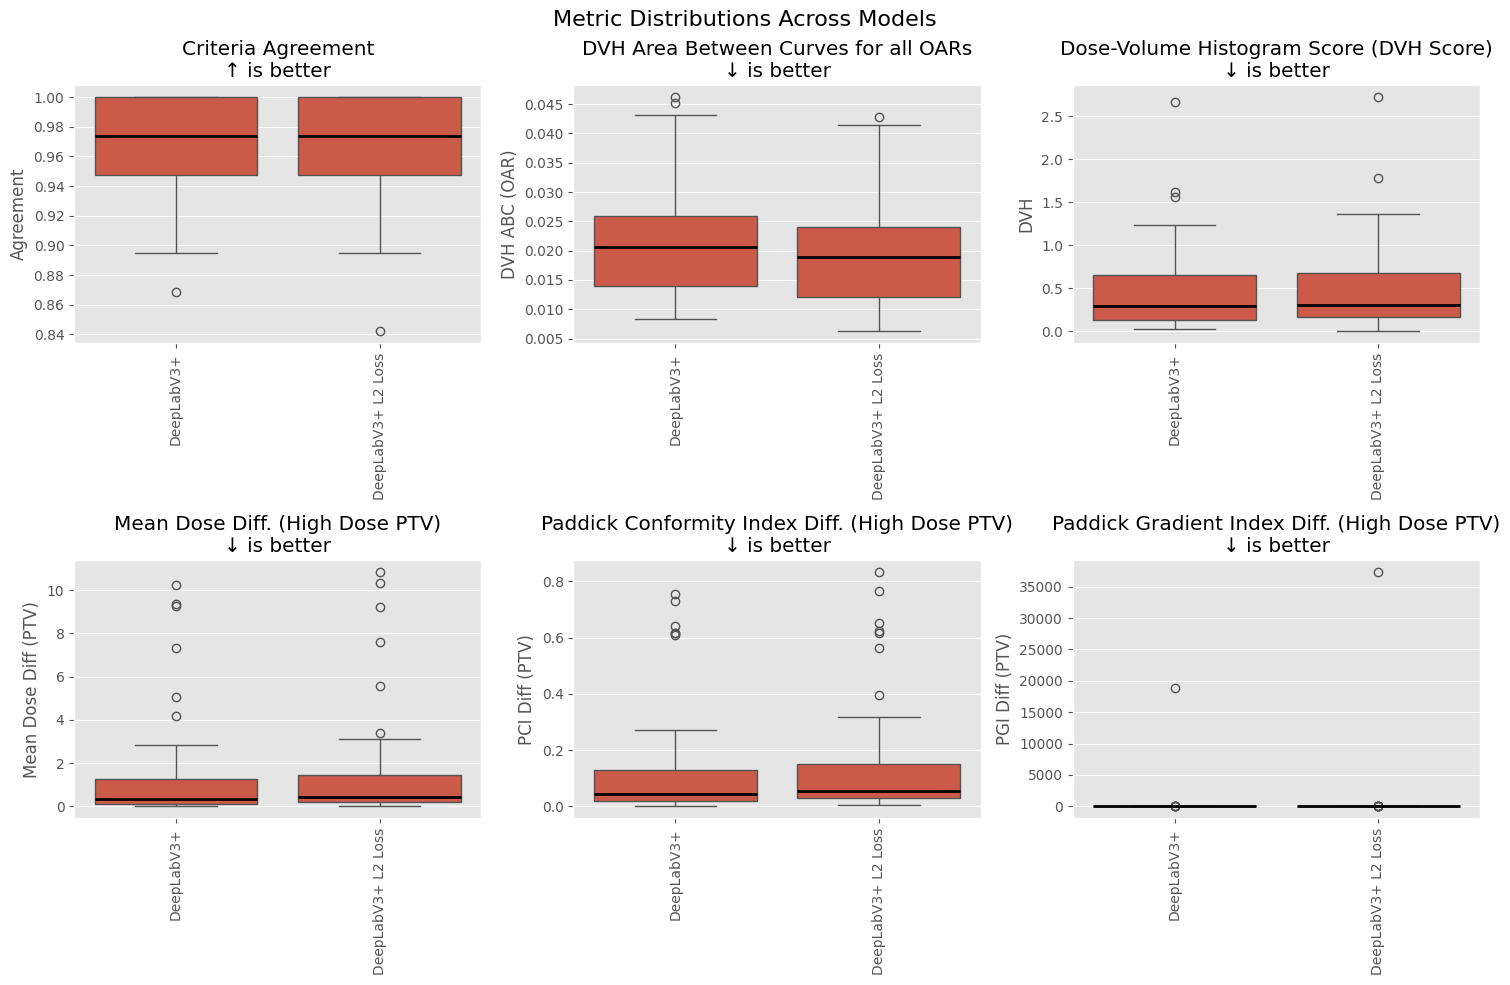

In [28]:
_ = deeplabv3plus_pred_comparison.plot_metric_distributions(METRICS_PRED)

# Dose Planning

In [29]:
plan_comparison = ModelComparison([
  mamba_199_plan,
  beamdiff_199_plan,
  spdiffdose_199_plan,
  dosediff_199_plan,
  diffdp_199_plan,
  ddpm_mednext_m_199_plan,
  c3d_2d_199_plan,
  mednext_m_199_plan,
  mednext_v2_m_199_plan,
  deeplabv3plus_199_plan,
  hdunet_199_plan,
], [
  'MD-Dose',
  'BeamDiff',
  'SPDiffDose',
  'DoseDiff',
  'DiffDP',
  'DDPM-MedNeXt-M',
  'C3D-2D',
  'MedNeXt-M',
  'MedNeXt-M v2',
  'DeepLabV3+',
  'HDUNet',
],
[
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'Diffusion',
  'UNet',
  'UNet',
  'UNet',
  'UNet',
  'UNet',
])

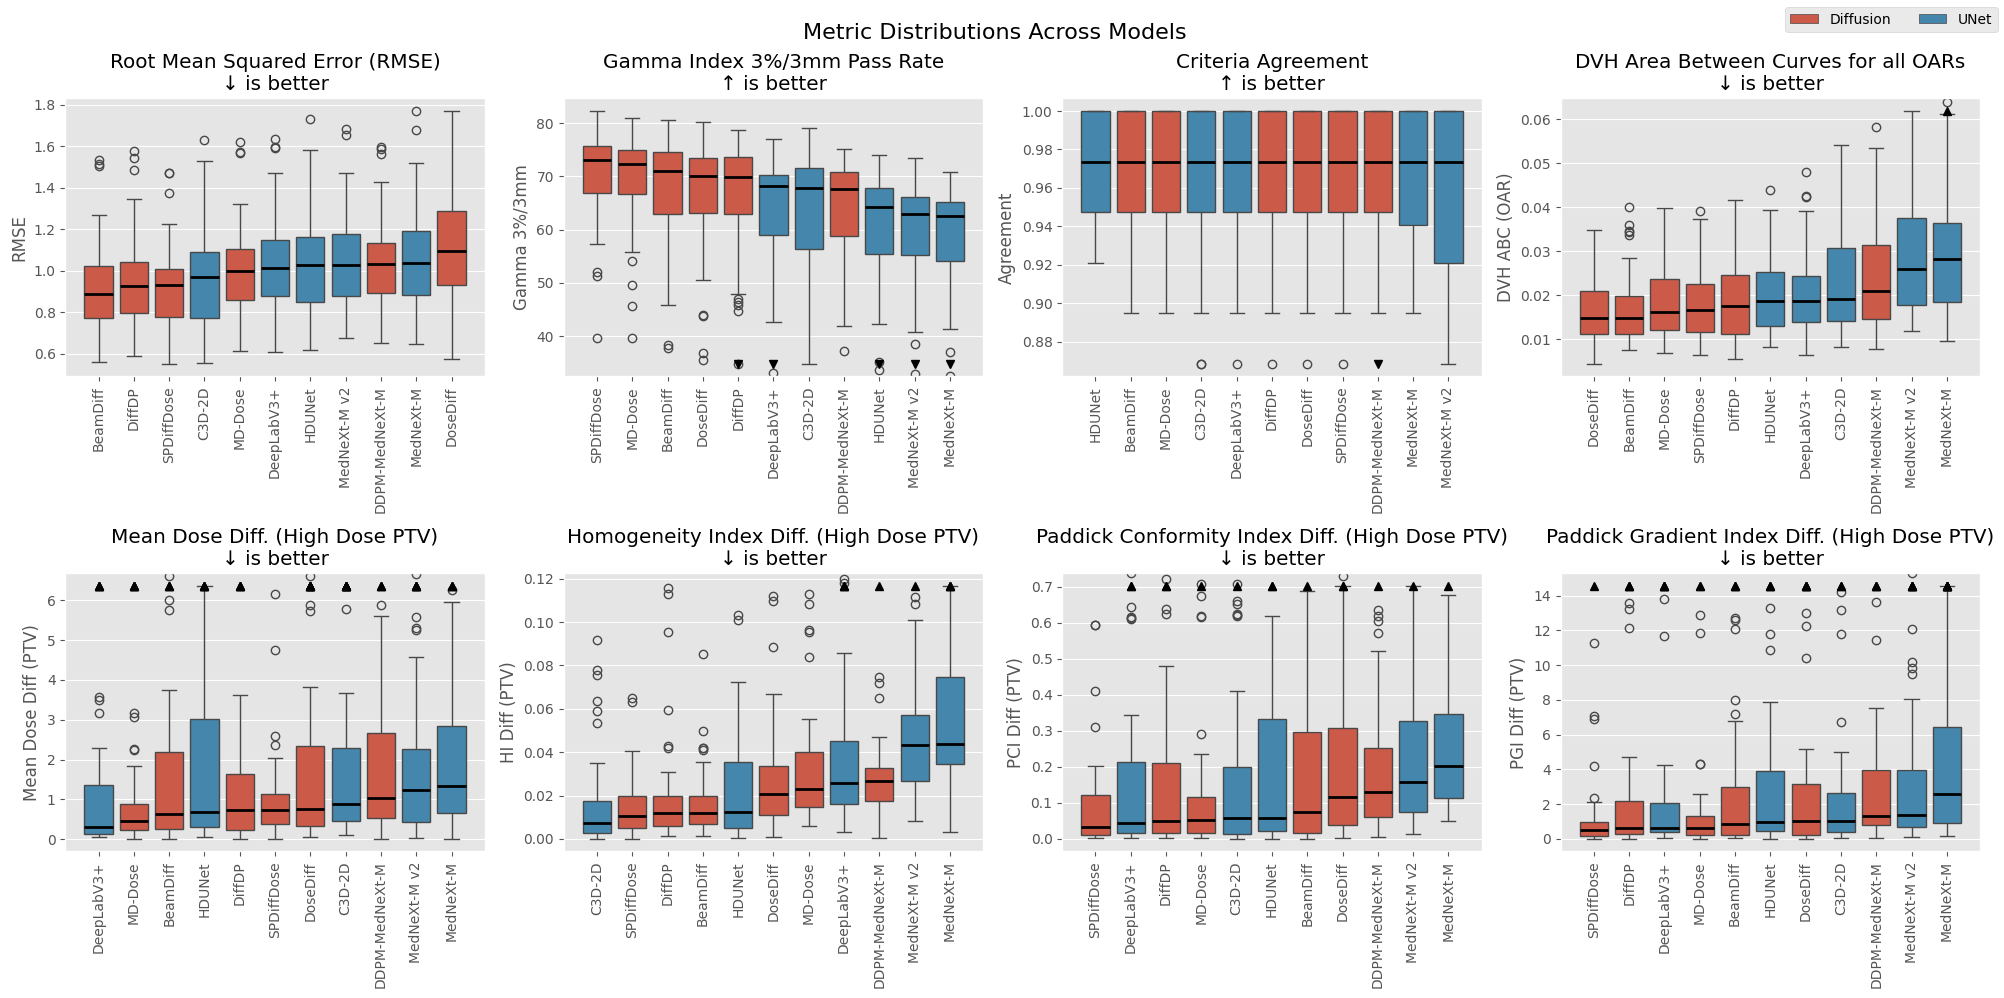

In [30]:
_ = plan_comparison.plot_metric_distributions(METRICS_PLAN_EXTENDED, sort=True, outliers=False)

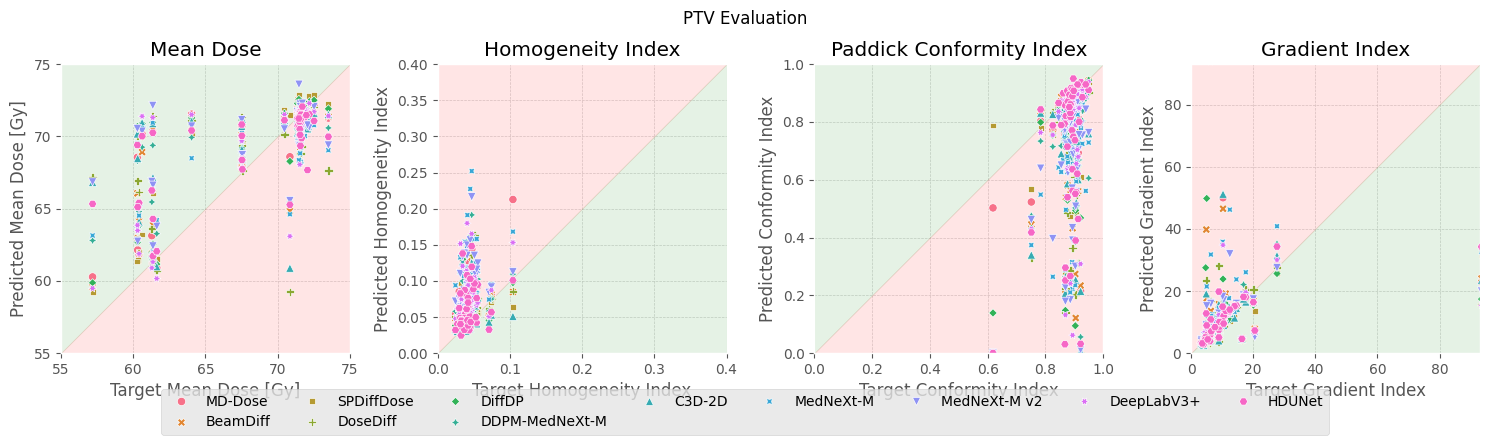

In [31]:
_ = plan_comparison.plot_ptv_evaluation()

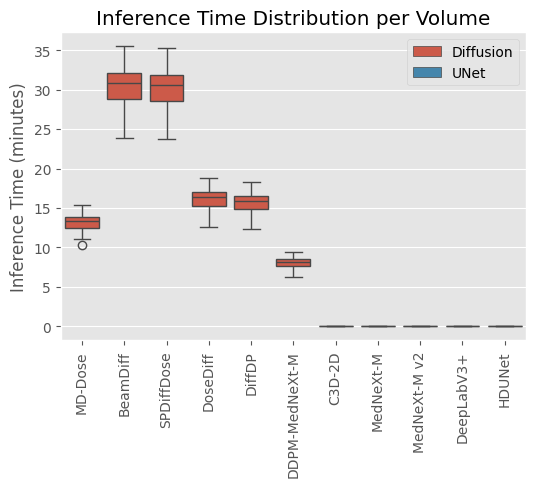

In [32]:
_ = plan_comparison.plot_inference_times()

0.5365081787109376


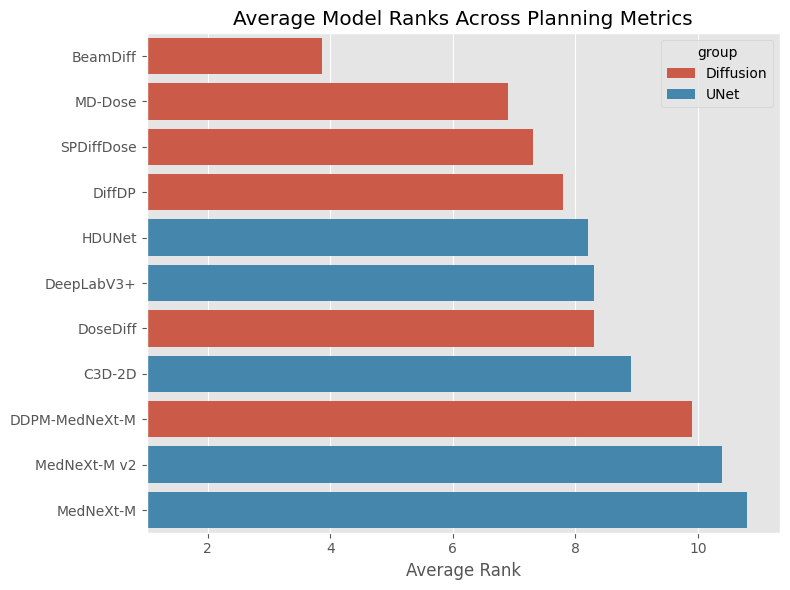

In [33]:
CORE_METRICS_PLAN = [
  'vol_rmse',
  'vol_gamma_3_3/pass_rate',
  'vol_agreement/agreement_all',
  'vol_dvh_auc/OAR/diff',
  'vol_mean_dose/high/abs_diff',
]

ADDITIONAL_METRICS_PLAN = [
  'vol_homogeneity_index/high/abs_diff',
  'vol_paddick_conformity_index/high/abs_diff',
  'vol_gradient_index/high/abs_diff'
]

mean_dose_diff = pd.concat([r.volume_metrics['vol_mean_dose/high/abs_diff'] for r in plan_comparison.results_list])
tau = mean_dose_diff.quantile(0.4)
print(tau)

median_dose_diffs = [r.volume_metrics['vol_mean_dose/high/abs_diff'].median() for r in plan_comparison.results_list]

ranks = []
for metric in CORE_METRICS_PLAN + ADDITIONAL_METRICS_PLAN:
  scores = []
  iqr = []
  ranges = []
  for r in plan_comparison.results_list:
    scores.append(r.volume_metrics[metric].median())
    iqr.append(r.volume_metrics[metric].quantile(0.75) - r.volume_metrics[metric].quantile(0.25))
    ranges.append(r.volume_metrics[metric].max() - r.volume_metrics[metric].min())

  data = pd.DataFrame({
    'median': scores,
    'iqr': iqr,
    'range': ranges,
  }, index=plan_comparison.result_labels)
  data = data.sort_values(['median', 'iqr', 'range'], ascending=[not is_higher_better(metric), True, True])
  data['rank'] = range(1, len(data) + 1)
  ranks.append(data['rank'])

ranks = pd.DataFrame(ranks, index=CORE_METRICS_PLAN + ADDITIONAL_METRICS_PLAN).T
ranks['core_rank'] = ranks[CORE_METRICS_PLAN].mean(axis=1)
ranks['ptv_rank'] = ranks[ADDITIONAL_METRICS_PLAN].mean(axis=1)
ranks['gate'] = median_dose_diffs
ranks['gate'] = [1 if diff <= tau else 0 for diff in ranks['gate']]
ranks['ptv_rank'] = ranks['gate'] * ranks['ptv_rank'] + (1 - ranks['gate']) * (len(ranks))

ranks['avg_rank'] = ranks[['core_rank', 'ptv_rank']].mean(axis=1)
ranks = ranks.sort_values('avg_rank')
ranks['group'] = pd.Series(plan_comparison.result_groups, index=plan_comparison.result_labels)
ranks = ranks.reset_index(names='model')

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(ranks, x='avg_rank', y='model', hue='group', ax=ax)
ax.set_xlabel('Average Rank')
ax.set_ylabel('')
ax.set_title('Average Model Ranks Across Planning Metrics')
ax.set_xlim(1)
plt.tight_layout()

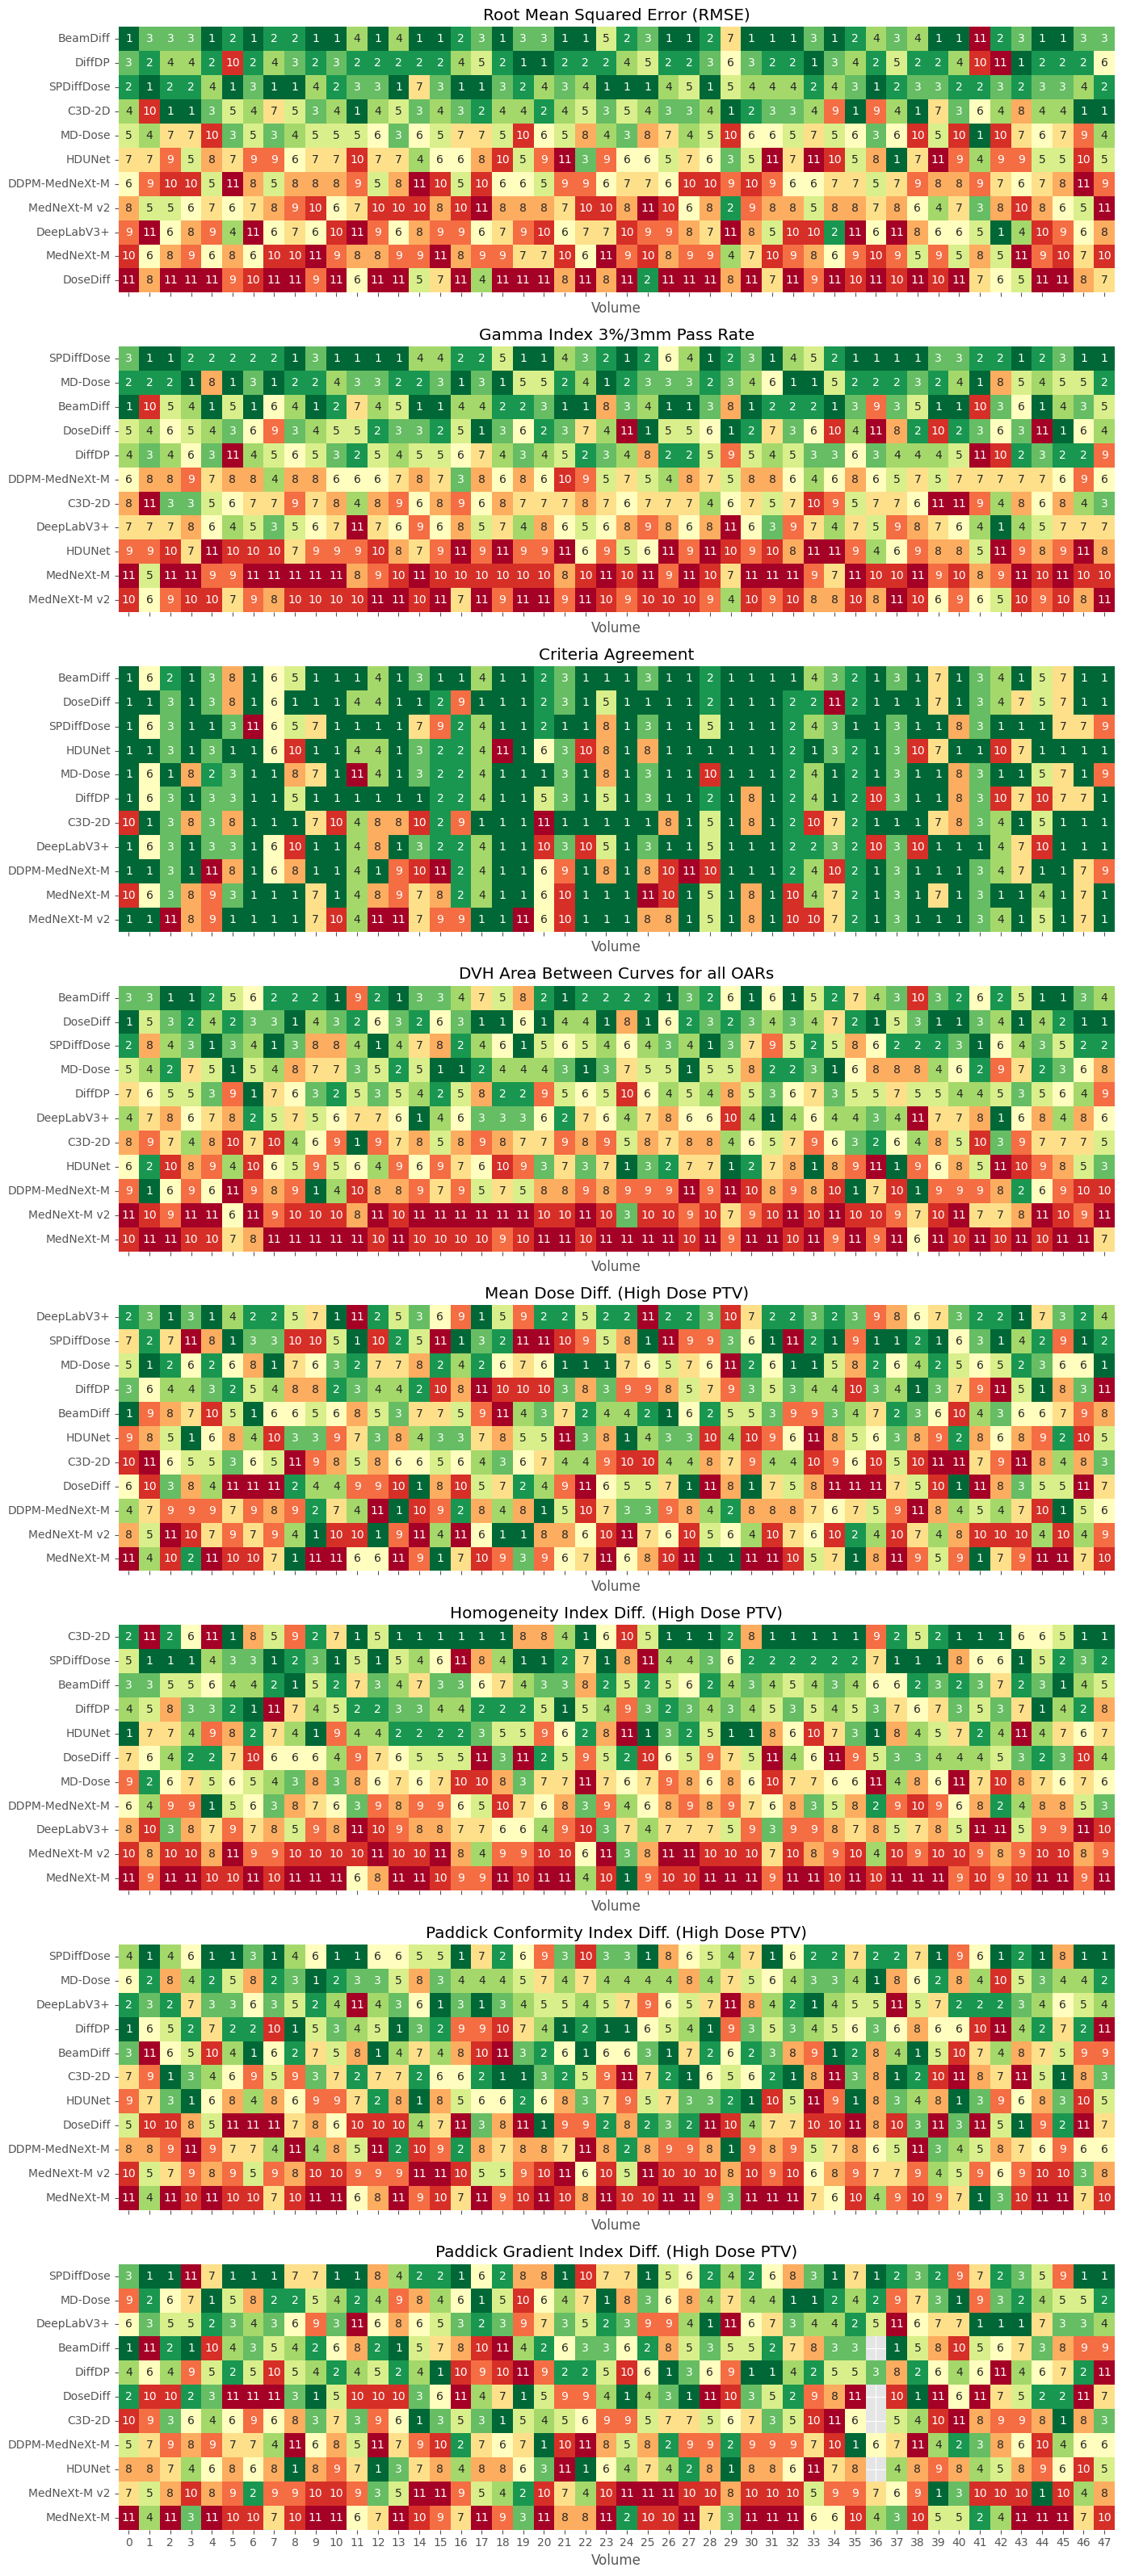

In [34]:
_ = plot_rank_heatmaps(plan_comparison, CORE_METRICS_PLAN + ADDITIONAL_METRICS_PLAN)

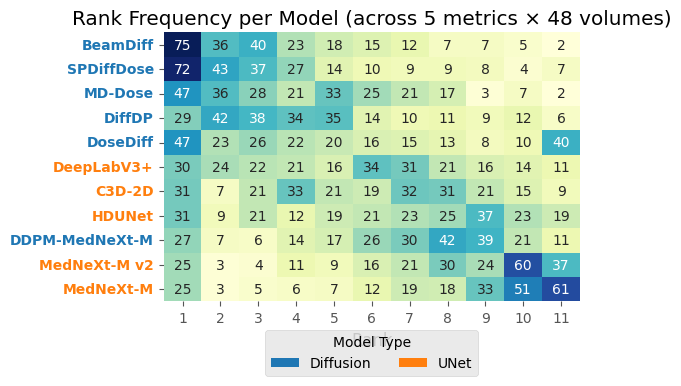

In [36]:
_ = plot_rank_frequency(plan_comparison, CORE_METRICS_PLAN)

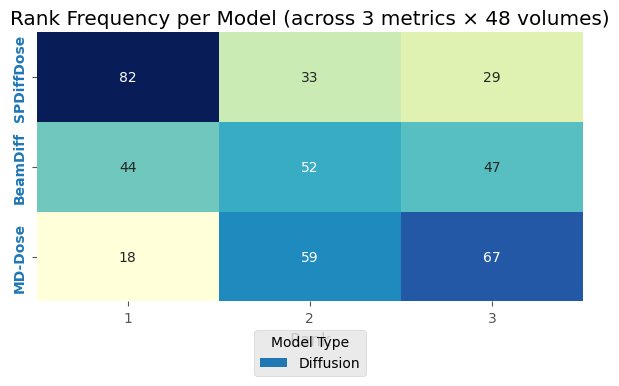

In [37]:
_ = plot_rank_frequency(ModelComparison(
	[beamdiff_199_plan, spdiffdose_199_plan, mamba_199_plan, diffdp_199_plan],
	['BeamDiff', 'SPDiffDose', 'MD-Dose'],
	['Diffusion', 'Diffusion', 'Diffusion']
), ADDITIONAL_METRICS_PLAN)

In [38]:
filtered_plan_comparison = ModelComparison([
  beamdiff_199_plan,
  spdiffdose_199_plan,
  deeplabv3plus_199_plan
], [
  'BeamDiff',
  'SPDiffDose',
  'DeepLabV3+'
], [
  'Diffusion',
  'Diffusion',
  'UNet'
])

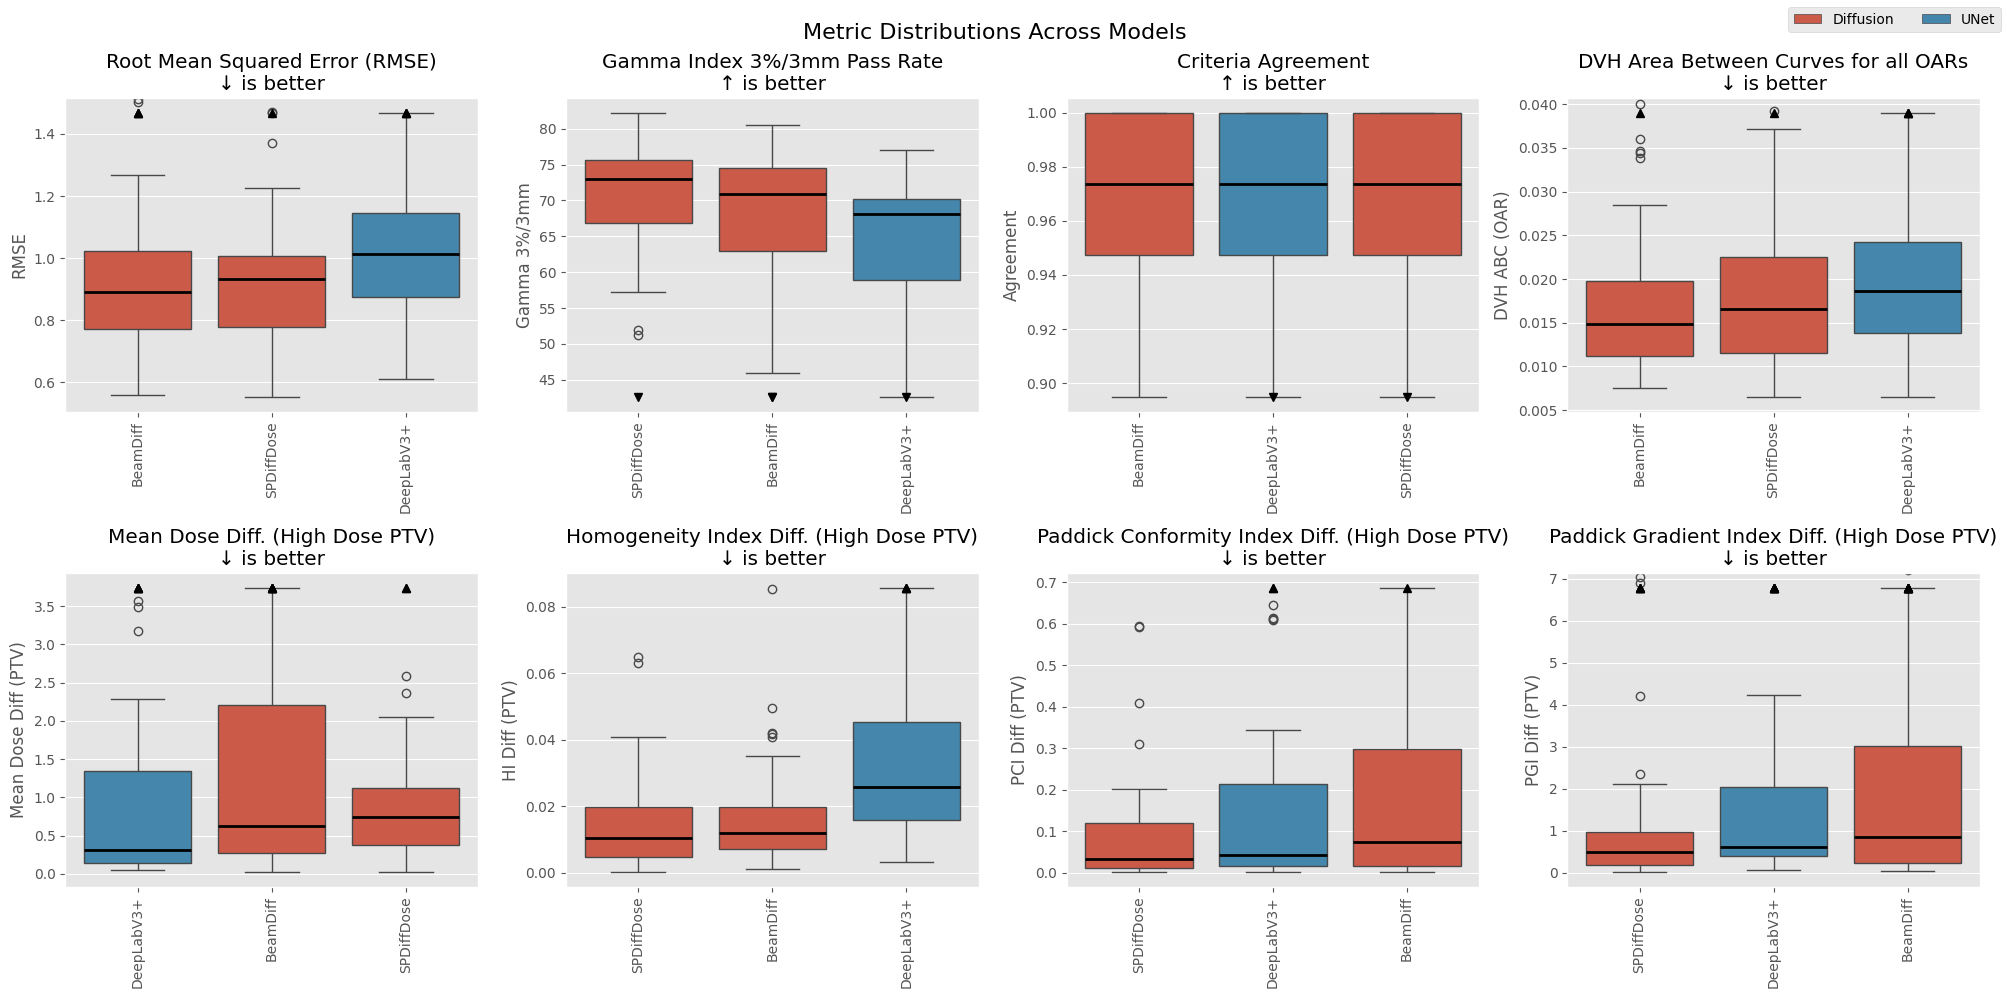

In [39]:
_ = filtered_plan_comparison.plot_metric_distributions(METRICS_PLAN_EXTENDED, sort=True, outliers=False)

ptv_masks (1, 3, 176, 160, 187)
oar_masks (1, 28, 176, 160, 187)
masks (29, 176, 160, 187)


<Axes: title={'center': 'DVH Comparison'}, xlabel='Dose (Gy)', ylabel='Volume Fraction ≥ Dose'>

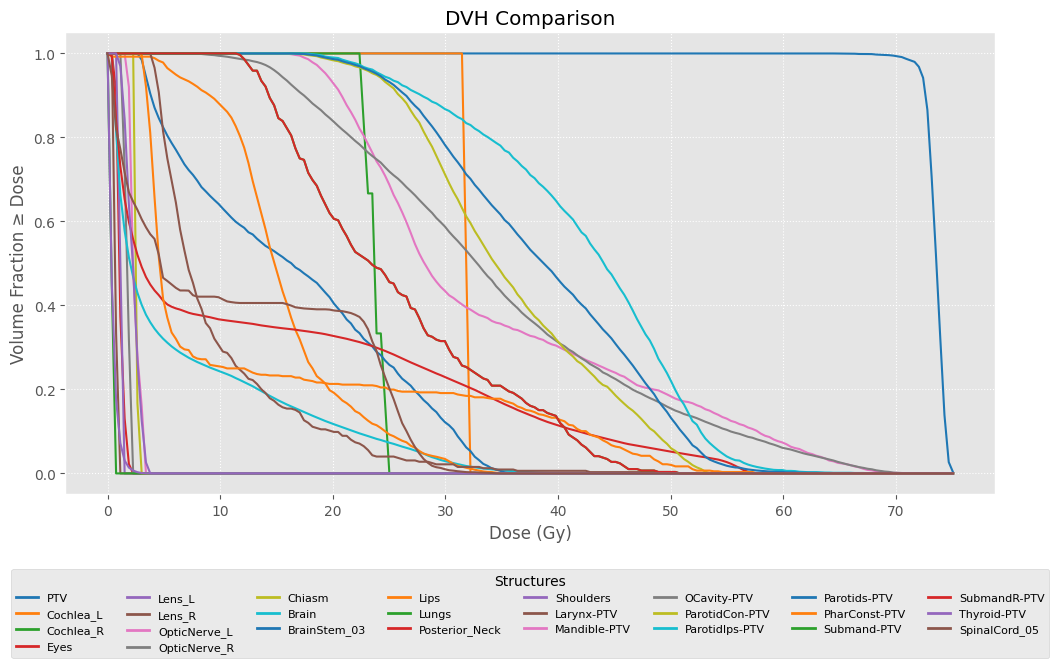

In [40]:
beamdiff_199_plan.for_sample('HNSCC-01-0078+A4Ac+MOS_12319').plot_volume_dvh()